## TAHAP 1 — Data Preparation, EDA, Decomposition, ACF/PACF, Feature Engineering, tf.data Pipeline
### Multivariate Multi-Horizon Forecasting of Bitcoin `Close` (24 hours ahead)

### 1. Imports, Seeds & GPU Configuration (Kaggle)


In [2]:
import os
import glob
import math
import random
import warnings

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from sklearn.preprocessing import MinMaxScaler
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import pacf
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

# --- GPU check / configuration ---
gpus = tf.config.list_physical_devices("GPU")
print("TensorFlow version :", tf.__version__)
print("GPUs detected      :", gpus)
if gpus:
    for g in gpus:
        try:
            tf.config.experimental.set_memory_growth(g, True)
        except RuntimeError as e:  # memory growth must be set before GPU init
            print("Memory growth warning:", e)
    print(f"-> Training will run on {len(gpus)} GPU(s).")
else:
    print("-> WARNING: no GPU found. Enable it: Kaggle > Settings > Accelerator > GPU.")

# --- Output directory (Kaggle working dir, falls back to cwd when run locally) ---
WORKING_DIR = "/kaggle/working" if os.path.isdir("/kaggle/working") else "."
os.makedirs(WORKING_DIR, exist_ok=True)
print("Working dir        :", os.path.abspath(WORKING_DIR))


TensorFlow version : 2.20.0
GPUs detected      : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]
-> Training will run on 2 GPU(s).
Working dir        : /kaggle/working


### 2. Global Configuration


In [3]:
# %%
HORIZON = 24            # forecast 24 steps (24 hours) ahead
TARGET = "Close"
TRAIN_RATIO = 0.70      # chronological split: 70% train
VAL_RATIO = 0.15        # 15% validation, remaining 15% test
ROLL_WINDOW = 24        # rolling-statistics window (1 day of hourly data)

BATCH_SIZE = 256        # training batch size (good fit for Kaggle T4/P100 with small LSTMs)
EVAL_BATCH_SIZE = 512   # larger batch for val/test (no gradients -> less memory)

# Window size is derived from the ACF/PACF analysis (section 8).
# Set to an int (e.g. 48) only if you want to override the automatic choice.
WINDOW_SIZE_OVERRIDE = None
MAX_LAG_CANDIDATE = 48  # maximum lag considered when choosing the window from PACF

# Set DATA_PATH manually if auto-detection fails, e.g.
# DATA_PATH = "/kaggle/input/<your-dataset>/<file>.csv"
DATA_PATH = "/kaggle/input/datasets/muhammadputraharifin/bitcoin3/Bitcoin3.csv"


### 3. Load Dataset


In [4]:
def find_dataset_csv():
    """Locate the bitcoin CSV inside /kaggle/input (or the current folder locally)."""
    roots = ["/kaggle/input", "."]
    candidates = []
    for r in roots:
        candidates += glob.glob(os.path.join(r, "**", "*.csv"), recursive=True)
    if not candidates:
        raise FileNotFoundError("No CSV found. Add the dataset to the notebook or set DATA_PATH.")
    preferred = [c for c in candidates if any(k in os.path.basename(c).lower() for k in ("btc", "bitcoin"))]
    if preferred:
        return preferred[0]
    if len(candidates) == 1:
        return candidates[0]
    print("Multiple CSV files found:")
    for c in candidates:
        print("  -", c)
    raise ValueError("Ambiguous dataset. Please set DATA_PATH to the bitcoin CSV.")


csv_path = DATA_PATH or find_dataset_csv()
print("Using dataset:", csv_path)

raw = pd.read_csv(csv_path)
raw.columns = [c.strip().replace(" ", "_") for c in raw.columns]   # 'Volume USDT' -> 'Volume_USDT'

# If the file contains several coins, keep Bitcoin only.
for col in ("Symbol", "symbol", "Coin", "coin", "Ticker", "ticker"):
    if col in raw.columns:
        raw = raw[raw[col].astype(str).str.upper().str.contains("BTC")]
        break

BASE_FEATURES = ["Close", "Volume_USDT", "RSI", "MACD_Hist", "ATR", "KAMAO"]
required = ["Date"] + BASE_FEATURES
missing_cols = [c for c in required if c not in raw.columns]
if missing_cols:
    raise KeyError(f"Missing columns {missing_cols}. Available columns: {list(raw.columns)}")

df = raw[required].copy()
df["Date"] = pd.to_datetime(df["Date"], format='mixed')

df = (df.sort_values("Date")
        .drop_duplicates(subset="Date")
        .set_index("Date"))
df[BASE_FEATURES] = df[BASE_FEATURES].apply(pd.to_numeric, errors="coerce")

print(f"Shape            : {df.shape}")
print(f"Period           : {df.index.min()}  ->  {df.index.max()}")
display(df.head())
display(df.tail())



Using dataset: /kaggle/input/datasets/muhammadputraharifin/bitcoin3/Bitcoin3.csv
Shape            : (53150, 6)
Period           : 2017-09-21 09:00:00  ->  2023-10-19 23:00:00


,Close,Volume_USDT,RSI,MACD_Hist,ATR,KAMAO
Date,,,,,,
2017-09-21 09:00:00,3860.00,74434.891166,49.192454,-48.279697,88.054720,2.495591
2017-09-21 10:00:00,3871.48,44687.318944,49.233202,-47.780476,87.996283,2.616710
2017-09-21 11:00:00,3864.95,80546.171672,49.210685,-47.308061,87.897128,2.532239
2017-09-21 12:00:00,3858.08,90331.531390,49.186948,-46.863233,87.720856,2.447245
2017-09-21 13:00:00,3856.67,103405.818040,49.182064,-46.425379,87.578086,2.424654


,Close,Volume_USDT,RSI,MACD_Hist,ATR,KAMAO
Date,,,,,,
2023-10-19 19:00:00,28750.75,2.984059e+07,53.630054,109.926882,129.065981,7.459700
2023-10-19 20:00:00,28715.38,4.997623e+07,53.531282,111.721905,129.268969,7.118597
2023-10-19 21:00:00,28604.09,3.205666e+07,53.221944,113.055031,129.287930,6.210037
2023-10-19 22:00:00,28649.65,2.200420e+07,53.332673,114.513131,129.219782,6.515616
2023-10-19 23:00:00,28713.71,1.758298e+07,53.487941,116.161806,129.096002,6.963753


### 4. Data Quality Check (hourly continuity, missing values)


In [5]:
full_range = pd.date_range(df.index.min(), df.index.max(), freq="h")
n_gap = len(full_range) - len(df)
print(f"Missing hourly timestamps: {n_gap}")
print("NaN per column:\n", df.isna().sum())

if n_gap > 0:
    # Re-create a strict hourly grid so that "24 steps" always means exactly 24 hours.
    # Only short gaps (<= 6h) are interpolated using neighbouring values.
    df = df.reindex(full_range).rename_axis("Date")
    df = df.interpolate(method="time", limit=6)

df = df.dropna()
print("Shape after cleaning:", df.shape)
display(df.describe().T)


Missing hourly timestamps: 121
NaN per column:
 Close          0
Volume_USDT    0
RSI            0
MACD_Hist      0
ATR            0
KAMAO          0
dtype: int64
Shape after cleaning: (53190, 6)


,count,mean,std,min,25%,50%,75%,max
Close,53190.0,2.059672e+04,1.582497e+04,3172.050000,7.969950e+03,1.388176e+04,2.965368e+04,6.863369e+04
Volume_USDT,53190.0,6.916936e+07,1.058736e+08,0.000000,1.011593e+07,2.767701e+07,8.940927e+07,3.005634e+09
RSI,53190.0,5.040541e+01,3.211970e+00,35.178834,4.829746e+01,5.004080e+01,5.241012e+01,6.465711e+01
MACD_Hist,53190.0,6.124859e-01,3.534807e+02,-1885.690630,-1.151681e+02,1.022419e+01,1.224298e+02,1.430406e+03
ATR,53190.0,2.216009e+02,2.084717e+02,17.436266,7.262624e+01,1.283529e+02,3.256798e+02,1.004531e+03
KAMAO,53190.0,2.281415e-01,5.170493e+00,-31.767152,-2.720697e+00,-3.366013e-02,3.163444e+00,3.974030e+01


### 5. Exploratory Data Analysis


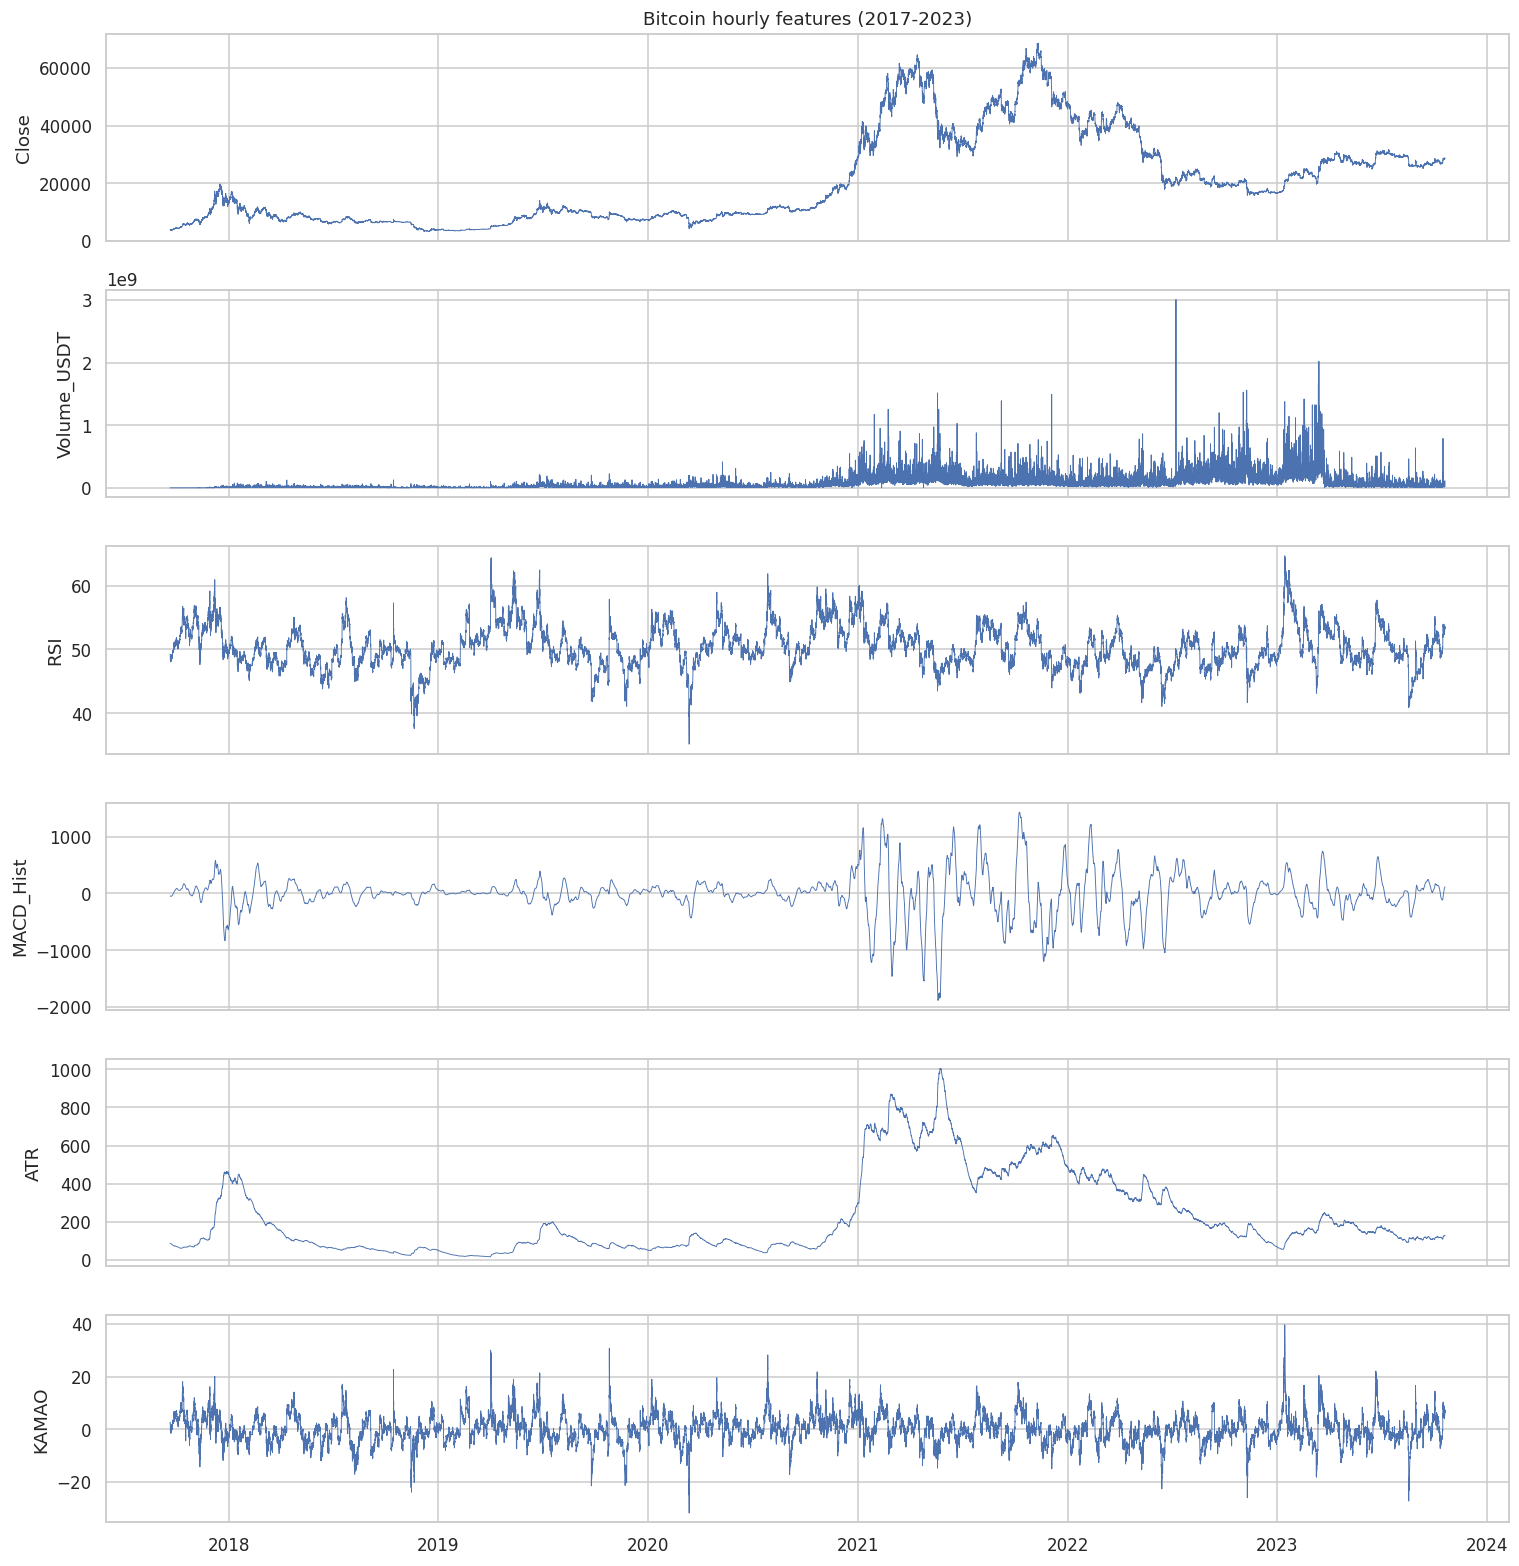

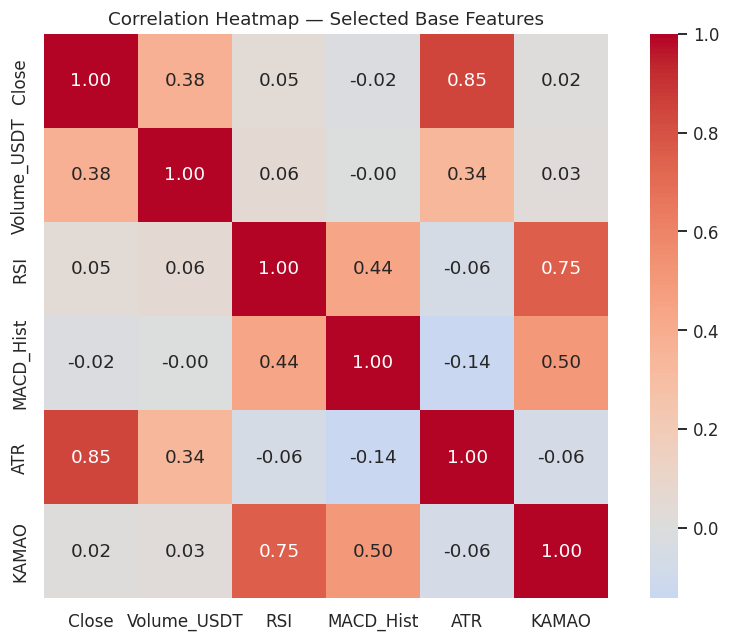

In [6]:
# 5.1 Time-series plots of every selected feature
fig, axes = plt.subplots(len(BASE_FEATURES), 1, figsize=(14, 2.4 * len(BASE_FEATURES)), sharex=True)
for ax, col in zip(axes, BASE_FEATURES):
    ax.plot(df.index, df[col], linewidth=0.6)
    ax.set_ylabel(col)
axes[0].set_title("Bitcoin hourly features (2017-2023)")
plt.tight_layout()
plt.show()

# %%
# 5.2 Correlation heatmap — base features
plt.figure(figsize=(8, 6))
sns.heatmap(df[BASE_FEATURES].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True)
plt.title("Correlation Heatmap — Selected Base Features")
plt.tight_layout()
plt.show()


### 6. Feature Engineering (Rolling Statistics)


Final feature list: ['Close', 'Volume_USDT', 'RSI', 'MACD_Hist', 'ATR', 'KAMAO', 'Close_roll_mean_24', 'Close_roll_std_24', 'Volume_roll_mean_24']
Shape: (53167, 9)


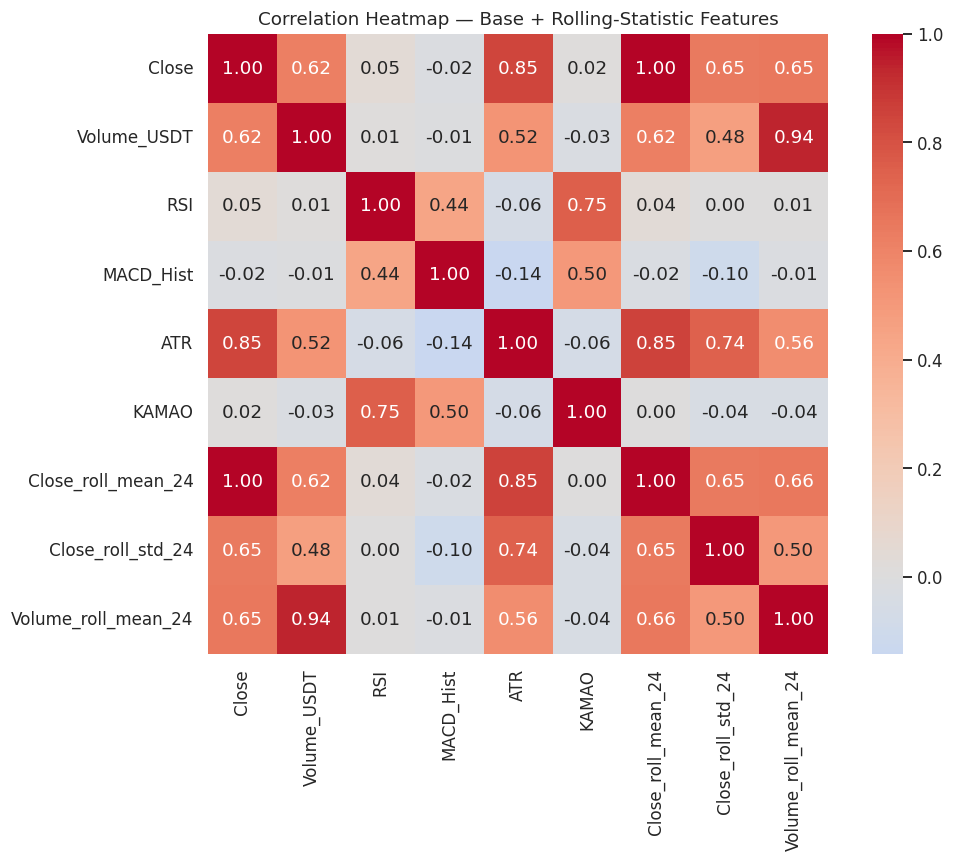

In [7]:
# * `Volume_USDT` is heavy-tailed, so a **stateless** `log1p` transform is applied (no statistics are learned from the data -> no leakage).
# * Rolling statistics use a **trailing** window (only past values), so they cannot leak future information.

# %%
df["Volume_USDT"] = np.log1p(df["Volume_USDT"])

df[f"Close_roll_mean_{ROLL_WINDOW}"] = df["Close"].rolling(ROLL_WINDOW).mean()
df[f"Close_roll_std_{ROLL_WINDOW}"] = df["Close"].rolling(ROLL_WINDOW).std()
df[f"Volume_roll_mean_{ROLL_WINDOW}"] = df["Volume_USDT"].rolling(ROLL_WINDOW).mean()

df = df.dropna()   # first (ROLL_WINDOW - 1) rows have no rolling value

FEATURES = list(df.columns)            # 'Close' stays at index 0 -> target index
assert FEATURES[0] == TARGET
TARGET_IDX = FEATURES.index(TARGET)
N_FEATURES = len(FEATURES)
print("Final feature list:", FEATURES)
print("Shape:", df.shape)

# %%
# Correlation heatmap — including the engineered features
plt.figure(figsize=(10, 8))
sns.heatmap(df[FEATURES].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True)
plt.title("Correlation Heatmap — Base + Rolling-Statistic Features")
plt.tight_layout()
plt.show()


### 7. Chronological Split (BEFORE any scaling)


Train:  37216  (2017-09-22 08:00:00 -> 2021-12-24 08:00:00)
Val  :   7975  (2021-12-24 09:00:00 -> 2022-11-21 15:00:00)
Test :   7976  (2022-11-21 16:00:00 -> 2023-10-19 23:00:00)


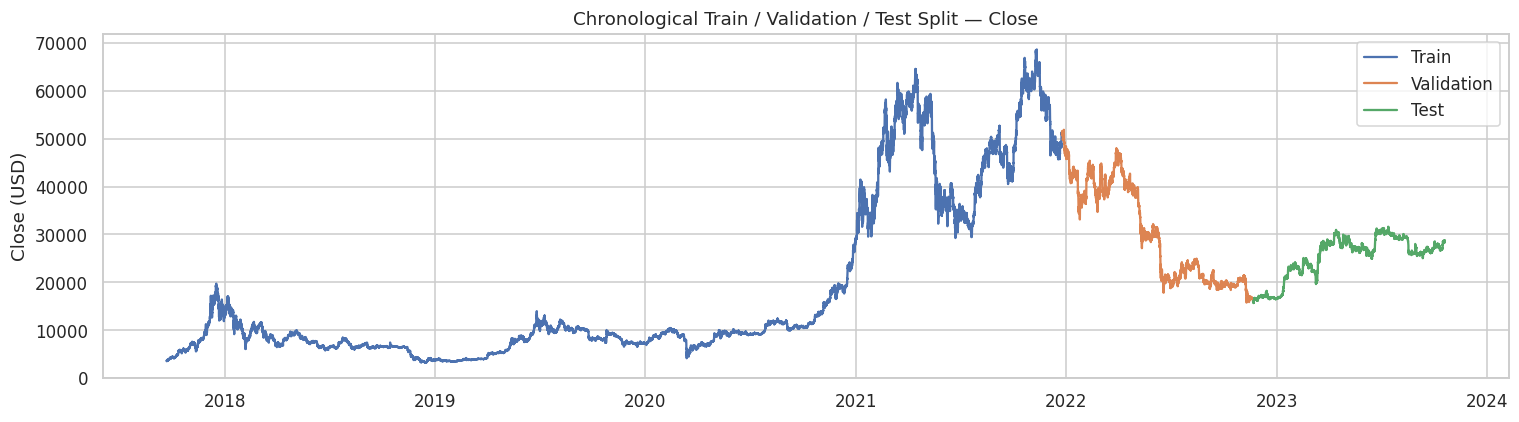

In [8]:
# Time series must be split in temporal order (no shuffling) to keep the test set strictly in the future.

# %%
n_total = len(df)
train_end = int(n_total * TRAIN_RATIO)
val_end = int(n_total * (TRAIN_RATIO + VAL_RATIO))

train_df = df.iloc[:train_end]
val_df = df.iloc[train_end:val_end]
test_df = df.iloc[val_end:]

print(f"Train: {len(train_df):>6}  ({train_df.index.min()} -> {train_df.index.max()})")
print(f"Val  : {len(val_df):>6}  ({val_df.index.min()} -> {val_df.index.max()})")
print(f"Test : {len(test_df):>6}  ({test_df.index.min()} -> {test_df.index.max()})")

plt.figure(figsize=(14, 4))
plt.plot(train_df.index, train_df[TARGET], label="Train")
plt.plot(val_df.index, val_df[TARGET], label="Validation")
plt.plot(test_df.index, test_df[TARGET], label="Test")
plt.title("Chronological Train / Validation / Test Split — Close")
plt.ylabel("Close (USD)")
plt.legend()
plt.tight_layout()
plt.show()


### 8. Target Decomposition (Close)


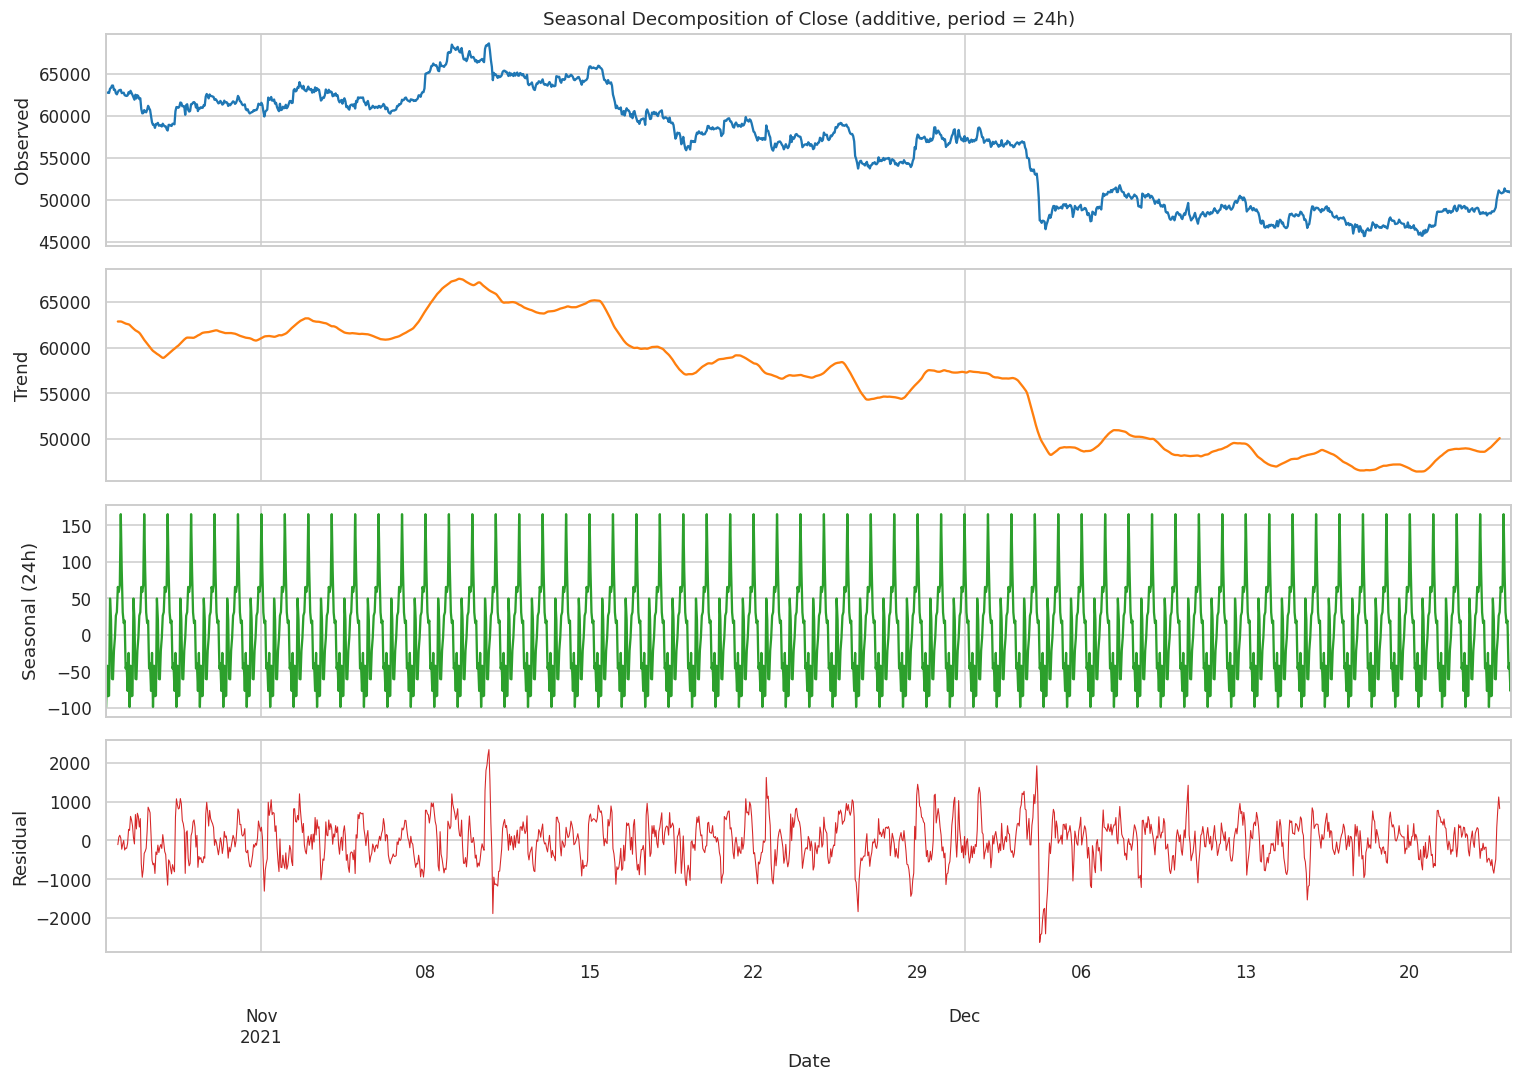

Trend strength    : 0.993
Seasonal strength : 0.014  (daily pattern)


In [9]:
# Additive decomposition with a daily period (24 h). The last ~60 days of the **training** set are plotted for readability.

# %%
DECOMP_PERIOD = 24
decomp_series = train_df[TARGET].iloc[-24 * 60:]
decomp = seasonal_decompose(decomp_series, model="additive", period=DECOMP_PERIOD)

fig, axes = plt.subplots(4, 1, figsize=(14, 10), sharex=True)
decomp.observed.plot(ax=axes[0], color="tab:blue");   axes[0].set_ylabel("Observed")
decomp.trend.plot(ax=axes[1], color="tab:orange");    axes[1].set_ylabel("Trend")
decomp.seasonal.plot(ax=axes[2], color="tab:green");  axes[2].set_ylabel("Seasonal (24h)")
decomp.resid.plot(ax=axes[3], color="tab:red", linewidth=0.7); axes[3].set_ylabel("Residual")
axes[0].set_title("Seasonal Decomposition of Close (additive, period = 24h)")
plt.tight_layout()
plt.show()

resid = decomp.resid.dropna()
seas = decomp.seasonal.loc[resid.index]
trend = decomp.trend.loc[resid.index]
seasonal_strength = max(0.0, 1 - resid.var() / (seas + resid).var())
trend_strength = max(0.0, 1 - resid.var() / (trend + resid).var())
print(f"Trend strength    : {trend_strength:.3f}")
print(f"Seasonal strength : {seasonal_strength:.3f}  (daily pattern)")

### 9. ACF & PACF Analysis → Window Size


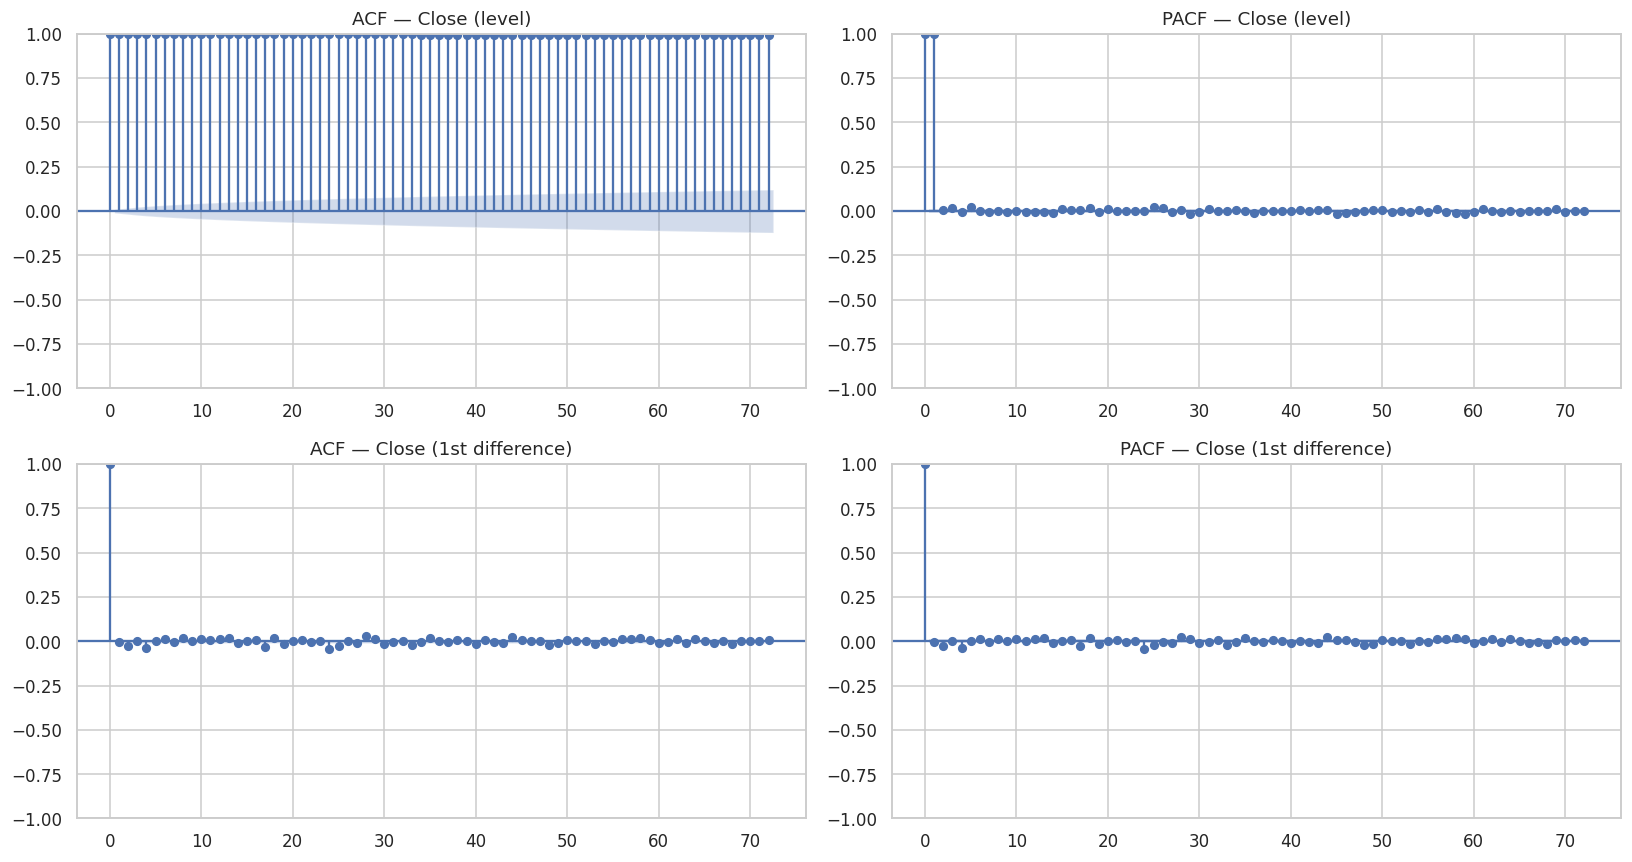

95% confidence bound        : ±0.0102
Significant PACF lags (<=72): [2, 4, 6, 8, 10, 12, 13, 17, 18, 19, 24, 25, 28, 30, 33, 35, 40, 44, 48, 49, 53, 56, 57, 58, 59, 62, 64, 68]
Strongest PACF lags         : [24, 4, 17, 2, 28, 25, 44, 48]
Last significant lag (<= 48) : 48
==> WINDOW_SIZE = 48 hours (derived from PACF, rounded up to a multiple of 24h)


In [10]:
# Computed on the **training** target only. Raw price is non-stationary (ACF decays very slowly),
# so the first difference (hourly price change) is analysed as well to find the meaningful lag memory.

# %%
NLAGS = 72
close_train = train_df[TARGET]
close_diff = close_train.diff().dropna()

fig, axes = plt.subplots(2, 2, figsize=(15, 8))
plot_acf(close_train, lags=NLAGS, ax=axes[0, 0], title="ACF — Close (level)")
plot_pacf(close_train, lags=NLAGS, ax=axes[0, 1], method="ywm", title="PACF — Close (level)")
plot_acf(close_diff, lags=NLAGS, ax=axes[1, 0], title="ACF — Close (1st difference)")
plot_pacf(close_diff, lags=NLAGS, ax=axes[1, 1], method="ywm", title="PACF — Close (1st difference)")
plt.tight_layout()
plt.show()

# %%
pacf_vals = pacf(close_diff, nlags=NLAGS, method="ywm")
conf = 1.96 / math.sqrt(len(close_diff))                 # 95% confidence bound
significant = [lag for lag in range(1, NLAGS + 1) if abs(pacf_vals[lag]) > conf]
top_lags = sorted(range(1, NLAGS + 1), key=lambda l: abs(pacf_vals[l]), reverse=True)[:8]

print(f"95% confidence bound        : ±{conf:.4f}")
print(f"Significant PACF lags (<=72): {significant}")
print(f"Strongest PACF lags         : {top_lags}")

candidates = [l for l in significant if l <= MAX_LAG_CANDIDATE]
last_sig = max(candidates) if candidates else HORIZON
# Round up to a multiple of the horizon (24h) and keep it in a sane range for LSTMs.
auto_window = int(min(max(math.ceil(last_sig / HORIZON) * HORIZON, HORIZON), 168))

WINDOW_SIZE = int(WINDOW_SIZE_OVERRIDE) if WINDOW_SIZE_OVERRIDE else auto_window
print(f"Last significant lag (<= {MAX_LAG_CANDIDATE}) : {last_sig}")
print(f"==> WINDOW_SIZE = {WINDOW_SIZE} hours "
      f"({'manual override' if WINDOW_SIZE_OVERRIDE else 'derived from PACF, rounded up to a multiple of 24h'})")


### 10. Scaling WITHOUT Data Leakage


In [11]:
# The `MinMaxScaler` is **fit on the training split only**; validation/test are only `transform`-ed.

# %%
scaler = MinMaxScaler(feature_range=(0, 1))
scaler.fit(train_df[FEATURES].values)                     # <-- TRAIN ONLY

train_scaled = scaler.transform(train_df[FEATURES].values).astype("float32")
val_scaled = scaler.transform(val_df[FEATURES].values).astype("float32")
test_scaled = scaler.transform(test_df[FEATURES].values).astype("float32")

# Leakage guards
assert scaler.n_samples_seen_ == len(train_df), "Scaler saw more than the training rows!"
assert np.allclose(scaler.data_max_, train_df[FEATURES].max().values), "Scaler statistics are not train-only!"
print("Leakage check passed: scaler statistics come from the training split only.")
print(f"Train range of Close (scaled): [{train_scaled[:, TARGET_IDX].min():.3f}, {train_scaled[:, TARGET_IDX].max():.3f}]")
print(f"Val   range of Close (scaled): [{val_scaled[:, TARGET_IDX].min():.3f}, {val_scaled[:, TARGET_IDX].max():.3f}]")
print(f"Test  range of Close (scaled): [{test_scaled[:, TARGET_IDX].min():.3f}, {test_scaled[:, TARGET_IDX].max():.3f}]")


def inverse_close(values_scaled):
    """Convert scaled Close values back to USD using the TRAIN-fitted scaler statistics."""
    values_scaled = np.asarray(values_scaled, dtype="float64")
    return values_scaled * scaler.data_range_[TARGET_IDX] + scaler.data_min_[TARGET_IDX]


scaler_path = os.path.join(WORKING_DIR, "scaler.pkl")
joblib.dump(scaler, scaler_path)
print("Scaler saved to:", scaler_path)


Leakage check passed: scaler statistics come from the training split only.
Train range of Close (scaled): [0.000, 1.000]
Val   range of Close (scaled): [0.192, 0.744]
Test  range of Close (scaled): [0.191, 0.434]
Scaler saved to: /kaggle/working/scaler.pkl


### 11. tf.data Pipeline (Windowing → Train / Validation / Test)


In [12]:
# Every sample is `((encoder_input, decoder_input), target)`:
# * `encoder_input` : `(WINDOW_SIZE, N_FEATURES)` — past window of all features
# * `decoder_input` : `(HORIZON, 1)` — teacher-forcing input = `[Close_{t}, y_1, ..., y_{23}]` (last known Close, then the true targets shifted right by one)
# * `target`        : `(HORIZON, 1)` — the next 24 Close values
#
# The baseline LSTM only needs `(encoder_input, target)` → use `baseline_view(ds)`.
#
# Validation/test windows are prefixed with the last `WINDOW_SIZE` rows of the *previous* split
# as **input context only** (past information), so every validation/test **target** lies strictly inside its own split.

# %%
def make_window_dataset(arr, shuffle=False, batch_size=BATCH_SIZE):
    """Efficient tf.data windowing via index slicing (no huge materialised window array)."""
    features = tf.constant(arr, dtype=tf.float32)                 # (T, F)
    target = tf.constant(arr[:, TARGET_IDX], dtype=tf.float32)    # (T,)
    n_windows = len(arr) - WINDOW_SIZE - HORIZON + 1
    if n_windows <= 0:
        raise ValueError("Split too short for the chosen WINDOW_SIZE + HORIZON.")

    def _build(i):
        x = tf.ensure_shape(features[i:i + WINDOW_SIZE], [WINDOW_SIZE, N_FEATURES])
        y = tf.ensure_shape(target[i + WINDOW_SIZE:i + WINDOW_SIZE + HORIZON], [HORIZON])
        last_known = target[i + WINDOW_SIZE - 1:i + WINDOW_SIZE]                  # (1,)
        dec_in = tf.concat([last_known, y[:-1]], axis=0)                          # (HORIZON,)
        return (x, tf.expand_dims(dec_in, -1)), tf.expand_dims(y, -1)

    ds = tf.data.Dataset.from_tensor_slices(tf.range(n_windows))
    if shuffle:
        ds = ds.shuffle(n_windows, seed=SEED, reshuffle_each_iteration=True)
    ds = ds.map(_build, num_parallel_calls=tf.data.AUTOTUNE, deterministic=not shuffle)
    ds = ds.batch(batch_size, drop_remainder=False)
    return ds.prefetch(tf.data.AUTOTUNE), n_windows


def baseline_view(ds):
    """Drop the decoder input -> (encoder_input, target) for the baseline LSTM."""
    return ds.map(lambda inputs, y: (inputs[0], y), num_parallel_calls=tf.data.AUTOTUNE).prefetch(tf.data.AUTOTUNE)


# Input context from the previous split (past data only)
val_input_arr = np.concatenate([train_scaled[-WINDOW_SIZE:], val_scaled], axis=0)
test_input_arr = np.concatenate([val_scaled[-WINDOW_SIZE:], test_scaled], axis=0)

train_ds, n_train_w = make_window_dataset(train_scaled, shuffle=True, batch_size=BATCH_SIZE)
val_ds, n_val_w = make_window_dataset(val_input_arr, shuffle=False, batch_size=EVAL_BATCH_SIZE)
test_ds, n_test_w = make_window_dataset(test_input_arr, shuffle=False, batch_size=EVAL_BATCH_SIZE)

assert n_val_w == len(val_df) - HORIZON + 1
assert n_test_w == len(test_df) - HORIZON + 1

print(f"Windows -> train: {n_train_w} | val: {n_val_w} | test: {n_test_w}")

# %%
# Sanity checks on the pipeline (shapes + teacher-forcing alignment)
(x_b, dec_b), y_b = next(iter(test_ds))
print("encoder input :", x_b.shape)
print("decoder input :", dec_b.shape)
print("target        :", y_b.shape)

# decoder input must be [last known Close, y_1 ... y_23]
assert np.isclose(x_b[0, -1, TARGET_IDX].numpy(), dec_b[0, 0, 0].numpy())
assert np.allclose(y_b[0, :-1, 0].numpy(), dec_b[0, 1:, 0].numpy())
# first test target must be the first test row
assert np.isclose(y_b[0, 0, 0].numpy(), test_scaled[0, TARGET_IDX])
print("Pipeline alignment check passed.")

# Timestamps of the test horizons (window i predicts test_df rows i ... i+23) — reused for plots/tables later
test_index = test_df.index

# %%
# Final summary of everything the next stages (custom layers, models, training loop) will need
print("=" * 60)
print("TAHAP 1 SUMMARY")
print("=" * 60)
print(f"Features ({N_FEATURES})   : {FEATURES}")
print(f"Target             : {TARGET} (index {TARGET_IDX})")
print(f"WINDOW_SIZE        : {WINDOW_SIZE}")
print(f"HORIZON            : {HORIZON}")
print(f"Batch size (train) : {BATCH_SIZE}")
print(f"Train / Val / Test : {len(train_df)} / {len(val_df)} / {len(test_df)} rows")
print(f"Datasets           : train_ds, val_ds, test_ds  -> ((enc_in, dec_in), y)")
print(f"Baseline helper    : baseline_view(ds)          -> (enc_in, y)")
print(f"Scaler             : fitted on train only, saved to {scaler_path}")


I0000 00:00:1792718557.565322      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1792718557.568539      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Windows -> train: 37145 | val: 7952 | test: 7953
encoder input : (512, 48, 9)
decoder input : (512, 24, 1)
target        : (512, 24, 1)
Pipeline alignment check passed.
TAHAP 1 SUMMARY
Features (9)   : ['Close', 'Volume_USDT', 'RSI', 'MACD_Hist', 'ATR', 'KAMAO', 'Close_roll_mean_24', 'Close_roll_std_24', 'Volume_roll_mean_24']
Target             : Close (index 0)
WINDOW_SIZE        : 48
HORIZON            : 24
Batch size (train) : 256
Train / Val / Test : 37216 / 7975 / 7976 rows
Datasets           : train_ds, val_ds, test_ds  -> ((enc_in, dec_in), y)
Baseline helper    : baseline_view(ds)          -> (enc_in, y)
Scaler             : fitted on train only, saved to /kaggle/working/scaler.pkl


## TAHAP 2 — Custom Layers & Model Architectures
#### * `CustomDense`, `CustomMultiHeadAttention`, `CustomLayerNormalization`, `CustomDropout` (all from scratch)
#### * Model 1: Baseline LSTM (Functional API)
#### * Model 2: Seq2Seq LSTM with Teacher Forcing (Model Subclassing) + autoregressive decoding method

#### Requires TensorFlow >= 2.16 (Keras 3), which is what current Kaggle images ship.

In [14]:
import os
import math
import shutil
 
import numpy as np
import tensorflow as tf
import keras
from keras import layers
from keras.saving import register_keras_serializable
 
print("TensorFlow:", tf.__version__, "| Keras:", keras.__version__)
if int(keras.__version__.split(".")[0]) < 3:
    print("WARNING: this code targets Keras 3 (TF >= 2.16). Older versions may fail to (de)serialize.")
 
# Values confirmed in TAHAP 1 (falls back to them if run standalone)
WINDOW_SIZE = globals().get("WINDOW_SIZE", 48)
HORIZON = globals().get("HORIZON", 24)
N_FEATURES = globals().get("N_FEATURES", 9)
TARGET_IDX = globals().get("TARGET_IDX", 0)
BATCH_SIZE = globals().get("BATCH_SIZE", 256)
WORKING_DIR = globals().get("WORKING_DIR", "/kaggle/working" if os.path.isdir("/kaggle/working") else ".")
 
# Architecture hyper-parameters
UNITS = 128          # LSTM / attention model width (keep encoder & decoder equal for cross-attention)
NUM_HEADS = 4
KEY_DIM = 32         # per-head dimension  (NUM_HEADS * KEY_DIM = 128 = UNITS)
DROPOUT_RATE = 0.1
 
PKG = "CustomTS"     # namespace for serialization registry

TensorFlow: 2.20.0 | Keras: 3.13.2


### 2. Custom Layers (from scratch)


In [15]:
@register_keras_serializable(package=PKG)
class CustomDense(layers.Layer):
    """Fully-connected layer: y = activation(x @ W + b). Works on any rank >= 2 (acts on the last axis)."""
 
    def __init__(self, units, activation=None, use_bias=True,
                 kernel_initializer="glorot_uniform", bias_initializer="zeros", **kwargs):
        super().__init__(**kwargs)
        self.units = int(units)
        self.activation = keras.activations.get(activation)
        self.use_bias = use_bias
        self.kernel_initializer = keras.initializers.get(kernel_initializer)
        self.bias_initializer = keras.initializers.get(bias_initializer)
 
    def build(self, input_shape):
        in_dim = int(input_shape[-1])
        self.kernel = self.add_weight(
            name="kernel", shape=(in_dim, self.units),
            initializer=self.kernel_initializer, trainable=True)
        if self.use_bias:
            self.bias = self.add_weight(
                name="bias", shape=(self.units,),
                initializer=self.bias_initializer, trainable=True)
        else:
            self.bias = None
 
    def call(self, inputs):
        outputs = tf.einsum("...i,io->...o", inputs, self.kernel)
        if self.bias is not None:
            outputs = outputs + self.bias
        return self.activation(outputs)
 
    def get_config(self):
        config = super().get_config()
        config.update({
            "units": self.units,
            "activation": keras.activations.serialize(self.activation),
            "use_bias": self.use_bias,
            "kernel_initializer": keras.initializers.serialize(self.kernel_initializer),
            "bias_initializer": keras.initializers.serialize(self.bias_initializer),
        })
        return config
 
 
# %%
@register_keras_serializable(package=PKG)
class CustomLayerNormalization(layers.Layer):
    """Layer normalisation over the last axis: gamma * (x - mean) / sqrt(var + eps) + beta."""
 
    def __init__(self, epsilon=1e-6, **kwargs):
        super().__init__(**kwargs)
        self.epsilon = float(epsilon)
 
    def build(self, input_shape):
        dim = int(input_shape[-1])
        self.gamma = self.add_weight(name="gamma", shape=(dim,), initializer="ones", trainable=True)
        self.beta = self.add_weight(name="beta", shape=(dim,), initializer="zeros", trainable=True)
 
    def call(self, inputs):
        mean, variance = tf.nn.moments(inputs, axes=[-1], keepdims=True)
        normalized = (inputs - mean) * tf.math.rsqrt(variance + self.epsilon)
        return normalized * self.gamma + self.beta
 
    def get_config(self):
        config = super().get_config()
        config.update({"epsilon": self.epsilon})
        return config
 
 
# %%
@register_keras_serializable(package=PKG)
class CustomDropout(layers.Layer):
    """Inverted dropout: randomly zeroes units with probability `rate` during training and rescales the rest."""
 
    def __init__(self, rate=0.1, **kwargs):
        super().__init__(**kwargs)
        if not 0.0 <= rate < 1.0:
            raise ValueError("rate must be in [0, 1).")
        self.rate = float(rate)
 
    def call(self, inputs, training=None):
        if not training or self.rate == 0.0:
            return inputs
        keep_prob = 1.0 - self.rate
        keep_mask = tf.random.uniform(tf.shape(inputs), dtype=inputs.dtype) >= self.rate
        return tf.where(keep_mask, inputs / keep_prob, tf.zeros_like(inputs))
 
    def get_config(self):
        config = super().get_config()
        config.update({"rate": self.rate})
        return config
 
 
# %%
@register_keras_serializable(package=PKG)
class CustomMultiHeadAttention(layers.Layer):
    """Multi-head scaled dot-product attention built with raw tensor ops (einsum / softmax).
 
    call(query, value, key=None):  key defaults to value.
        Q = query @ Wq, K = key @ Wk, V = value @ Wv        -> split into `num_heads` heads
        scores  = Q K^T / sqrt(key_dim)   (+ optional causal mask)
        weights = softmax(scores)         (+ optional attention dropout)
        heads   = weights @ V             -> concatenated + projected with Wo
    Output shape: (batch, T_query, output_dim) with output_dim = query feature size unless specified.
    """
 
    def __init__(self, num_heads, key_dim, output_dim=None, dropout_rate=0.0, use_bias=True,
                 kernel_initializer="glorot_uniform", **kwargs):
        super().__init__(**kwargs)
        self.num_heads = int(num_heads)
        self.key_dim = int(key_dim)
        self.output_dim = None if output_dim is None else int(output_dim)
        self.dropout_rate = float(dropout_rate)
        self.use_bias = use_bias
        self.kernel_initializer = keras.initializers.get(kernel_initializer)
        self.attn_dropout = CustomDropout(self.dropout_rate)
 
    def build(self, query_shape, value_shape=None, key_shape=None):
        value_shape = value_shape if value_shape is not None else query_shape
        key_shape = key_shape if key_shape is not None else value_shape
        q_dim, k_dim, v_dim = int(query_shape[-1]), int(key_shape[-1]), int(value_shape[-1])
        out_dim = self.output_dim or q_dim
        H, D = self.num_heads, self.key_dim
 
        def kernel(name, shape):
            return self.add_weight(name=name, shape=shape, initializer=self.kernel_initializer, trainable=True)
 
        def bias(name, shape):
            return self.add_weight(name=name, shape=shape, initializer="zeros", trainable=True) if self.use_bias else None
 
        self.wq, self.bq = kernel("wq", (q_dim, H, D)), bias("bq", (H, D))
        self.wk, self.bk = kernel("wk", (k_dim, H, D)), bias("bk", (H, D))
        self.wv, self.bv = kernel("wv", (v_dim, H, D)), bias("bv", (H, D))
        self.wo, self.bo = kernel("wo", (H, D, out_dim)), bias("bo", (out_dim,))
 
    def call(self, query, value, key=None, use_causal_mask=False, training=None):
        key = value if key is None else key
 
        # 1) linear projections -> (B, T, H, D)
        q = tf.einsum("btd,dhk->bthk", query, self.wq)
        k = tf.einsum("bsd,dhk->bshk", key, self.wk)
        v = tf.einsum("bsd,dhk->bshk", value, self.wv)
        if self.use_bias:
            q, k, v = q + self.bq, k + self.bk, v + self.bv
 
        # 2) scaled dot-product attention -> (B, H, Tq, Tv)
        scores = tf.einsum("bthk,bshk->bhts", q, k)
        scores = scores * tf.math.rsqrt(tf.cast(self.key_dim, scores.dtype))
        if use_causal_mask:
            t_q, t_v = tf.shape(scores)[-2], tf.shape(scores)[-1]
            causal = tf.linalg.band_part(tf.ones((t_q, t_v), dtype=scores.dtype), -1, 0)
            scores = scores + (1.0 - causal) * (-1e9)
        weights = tf.nn.softmax(scores, axis=-1)
        weights = self.attn_dropout(weights, training=training)
 
        # 3) weighted sum of values, concatenate heads and project: (B, Tq, out_dim)
        context = tf.einsum("bhts,bshk->bthk", weights, v)
        output = tf.einsum("bthk,hkd->btd", context, self.wo)   # == concat(heads) @ Wo
        if self.use_bias:
            output = output + self.bo
        return output
 
    def get_config(self):
        config = super().get_config()
        config.update({
            "num_heads": self.num_heads,
            "key_dim": self.key_dim,
            "output_dim": self.output_dim,
            "dropout_rate": self.dropout_rate,
            "use_bias": self.use_bias,
            "kernel_initializer": keras.initializers.serialize(self.kernel_initializer),
        })
        return config

### 3. Model 1 — Baseline LSTM (Functional API)
#### `LSTM → LayerNorm → Custom MHA (self-attention) + residual → LayerNorm → Dropout → LSTM → CustomDense → CustomDense(24) → Reshape (24, 1)`

In [16]:
def build_baseline_lstm(window_size=WINDOW_SIZE, n_features=N_FEATURES, horizon=HORIZON,
                        units=UNITS, num_heads=NUM_HEADS, key_dim=KEY_DIM,
                        dropout_rate=DROPOUT_RATE, name="baseline_lstm"):
    inputs = layers.Input(shape=(window_size, n_features), name="encoder_input")
 
    x = layers.LSTM(units, return_sequences=True, name="lstm_1")(inputs)
    x = CustomLayerNormalization(name="ln_1")(x)
 
    attn = CustomMultiHeadAttention(num_heads=num_heads, key_dim=key_dim, name="custom_mha")(x, x)
    x = layers.Add(name="residual_add")([x, attn])
    x = CustomLayerNormalization(name="ln_2")(x)
    x = CustomDropout(dropout_rate, name="drop_1")(x)
 
    x = layers.LSTM(units, name="lstm_2")(x)                         # last hidden state -> (B, units)
    x = CustomDense(units, activation="relu", name="dense_hidden")(x)
    x = CustomDropout(dropout_rate, name="drop_2")(x)
    x = CustomDense(horizon, name="dense_forecast")(x)               # (B, horizon)
    outputs = layers.Reshape((horizon, 1), name="forecast_reshape")(x)   # (B, horizon, 1)
 
    return keras.Model(inputs, outputs, name=name)
 
 
baseline_model = build_baseline_lstm()
baseline_model.summary()
 
# Dummy forward pass check
dummy_enc = tf.random.normal((BATCH_SIZE, WINDOW_SIZE, N_FEATURES))
dummy_out = baseline_model(dummy_enc, training=False)
print("Baseline output shape:", dummy_out.shape)
assert dummy_out.shape == (BATCH_SIZE, HORIZON, 1), "Baseline output shape mismatch!"
print("Baseline dummy forward pass OK.")

Model: "baseline_lstm"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ encoder_input       │ (None, 48, 9)     │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm_1 (LSTM)       │ (None, 48, 128)   │     70,656 │ encoder_input[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ ln_1                │ (None, 48, 128)   │        256 │ lstm_1[0][0]      │
│ (CustomLayerNormal… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ custom_mha          │ (None, 48, 128)   │     66,048 │ ln_1[0][0],       │
│ (CustomMultiHeadAt… │                   │            │ ln_1[0][0]        │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ residual_add (Add)  │ (None, 48, 128)   │          0 │ ln_1[0][0],       │
│                     │                   │            │ custom_mha[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ ln_2                │ (None, 48, 128)   │        256 │ residual_add[0][… │
│ (CustomLayerNormal… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ drop_1              │ (None, 48, 128)   │          0 │ ln_2[0][0]        │
│ (CustomDropout)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm_2 (LSTM)       │ (None, 128)       │    131,584 │ drop_1[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_hidden        │ (None, 128)       │     16,512 │ lstm_2[0][0]      │
│ (CustomDense)       │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ drop_2              │ (None, 128)       │          0 │ dense_hidden[0][… │
│ (CustomDropout)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_forecast      │ (None, 24)        │      3,096 │ drop_2[0][0]      │
│ (CustomDense)       │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ forecast_reshape    │ (None, 24, 1)     │          0 │ dense_forecast[0… │
│ (Reshape)           │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 288,408 (1.10 MB)

 Trainable params: 288,408 (1.10 MB)

 Non-trainable params: 0 (0.00 B)

Baseline output shape: (256, 24, 1)
Baseline dummy forward pass OK.


### 4. Model 2 — Seq2Seq LSTM with Teacher Forcing (Model Subclassing)
#### * **Encoder**: LSTM over the 48-step, 9-feature window → sequence outputs + final states `(h, c)`.
#### * **Decoder**: LSTM over the 24-step, 1-feature decoder input, initialised with `(h, c)`.
####   During training the decoder input is the **ground-truth** previous Close (teacher forcing, built in TAHAP 1).
#### * **Custom cross-attention**: every decoder step attends to all encoder outputs.
#### * **Head**: LayerNorm(residual) → Dropout → CustomDense(relu) → CustomDense(1).
#### * `autoregressive_predict()` runs the same layers step-by-step, feeding each prediction back as the next decoder input (used for test inference in TAHAP 4).

In [17]:
@register_keras_serializable(package=PKG)
class Seq2SeqLSTM(keras.Model):
    def __init__(self, units=UNITS, num_heads=NUM_HEADS, key_dim=KEY_DIM,
                 dropout_rate=DROPOUT_RATE, horizon=HORIZON, target_idx=TARGET_IDX, **kwargs):
        super().__init__(**kwargs)
        self.units = units
        self.num_heads = num_heads
        self.key_dim = key_dim
        self.dropout_rate = dropout_rate
        self.horizon = horizon
        self.target_idx = target_idx
 
        # Encoder
        self.encoder_lstm = layers.LSTM(units, return_sequences=True, return_state=True, name="encoder_lstm")
        self.encoder_norm = CustomLayerNormalization(name="encoder_norm")
        # Decoder
        self.decoder_lstm = layers.LSTM(units, return_sequences=True, return_state=True, name="decoder_lstm")
        self.cross_attention = CustomMultiHeadAttention(num_heads=num_heads, key_dim=key_dim, name="cross_attention")
        self.attn_norm = CustomLayerNormalization(name="attn_norm")
        self.dropout = CustomDropout(dropout_rate, name="decoder_dropout")
        self.dense_hidden = CustomDense(units, activation="relu", name="dense_hidden")
        self.dense_out = CustomDense(1, name="dense_out")
 
    # ---- building blocks shared by training (call) and autoregressive inference ----
    def _encode(self, encoder_input, training=None):
        enc_seq, h, c = self.encoder_lstm(encoder_input, training=training)
        return self.encoder_norm(enc_seq), h, c
 
    def _decode(self, decoder_input, enc_seq, states, training=None):
        dec_seq, h, c = self.decoder_lstm(decoder_input, initial_state=states, training=training)
        context = self.cross_attention(dec_seq, enc_seq, training=training)
        x = self.attn_norm(dec_seq + context)
        x = self.dropout(x, training=training)
        x = self.dense_hidden(x)
        return self.dense_out(x), h, c                          # (B, T_dec, 1)
 
    def call(self, inputs, training=None):
        """Teacher-forcing forward pass. inputs = (encoder_input, decoder_input)."""
        encoder_input, decoder_input = inputs
        enc_seq, h, c = self._encode(encoder_input, training=training)
        outputs, _, _ = self._decode(decoder_input, enc_seq, [h, c], training=training)
        return outputs                                           # (B, horizon, 1)
 
    def autoregressive_predict(self, encoder_input, steps=None):
        """Inference without ground truth: feed each prediction back as the next decoder input."""
        steps = steps or self.horizon
        enc_seq, h, c = self._encode(encoder_input, training=False)
        step_input = encoder_input[:, -1:, self.target_idx:self.target_idx + 1]   # last known Close (B, 1, 1)
        preds = []
        for _ in range(steps):
            y_t, h, c = self._decode(step_input, enc_seq, [h, c], training=False)
            preds.append(y_t)
            step_input = y_t
        return tf.concat(preds, axis=1)                          # (B, steps, 1)
 
    def get_config(self):
        config = super().get_config()
        config.update({
            "units": self.units, "num_heads": self.num_heads, "key_dim": self.key_dim,
            "dropout_rate": self.dropout_rate, "horizon": self.horizon, "target_idx": self.target_idx,
        })
        return config
 
 
seq2seq_model = Seq2SeqLSTM(name="seq2seq_lstm")
 
# Dummy forward pass check (also builds all weights)
dummy_dec = tf.random.normal((BATCH_SIZE, HORIZON, 1))
s2s_out = seq2seq_model((dummy_enc, dummy_dec), training=False)
print("Seq2Seq (teacher forcing) output shape:", s2s_out.shape)
assert s2s_out.shape == (BATCH_SIZE, HORIZON, 1), "Seq2Seq output shape mismatch!"
 
ar_out = seq2seq_model.autoregressive_predict(dummy_enc)
print("Seq2Seq (autoregressive) output shape :", ar_out.shape)
assert ar_out.shape == (BATCH_SIZE, HORIZON, 1), "Autoregressive output shape mismatch!"
seq2seq_model.summary()
print("Seq2Seq dummy forward pass OK.")
 

Seq2Seq (teacher forcing) output shape: (256, 24, 1)
Seq2Seq (autoregressive) output shape : (256, 24, 1)


Model: "seq2seq_lstm"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ encoder_lstm (LSTM)             │ ((256, 48, 128), (256, │        70,656 │
│                                 │ 128), (256, 128))      │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder_norm                    │ ?                      │           256 │
│ (CustomLayerNormalization)      │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder_lstm (LSTM)             │ ((256, 24, 128), (256, │        66,560 │
│                                 │ 128), (256, 128))      │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ cross_attention                 │ ?                      │        66,048 │
│ (CustomMultiHeadAttention)      │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ attn_norm                       │ ?                      │           256 │
│ (CustomLayerNormalization)      │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder_dropout (CustomDropout) │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_hidden (CustomDense)      │ ?                      │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_out (CustomDense)         │ ?                      │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 220,417 (861.00 KB)

 Trainable params: 220,417 (861.00 KB)

 Non-trainable params: 0 (0.00 B)

Seq2Seq dummy forward pass OK.


### 5. Sanity Checks: gradient flow & .keras serialization round-trip
#### * every trainable weight (including all custom layers) must receive a gradient;
#### * save to `.keras`, reload, and verify identical predictions (temporary files are removed afterwards).


In [18]:
def check_gradients(model, inputs, name):
    y_dummy = tf.random.normal((BATCH_SIZE, HORIZON, 1))
    with tf.GradientTape() as tape:
        pred = model(inputs, training=True)
        loss = tf.reduce_mean(tf.abs(pred - y_dummy))
    grads = tape.gradient(loss, model.trainable_variables)
    missing = [v.path for v, g in zip(model.trainable_variables, grads) if g is None]
    assert not missing, f"{name}: no gradient for {missing}"
    print(f"{name}: gradients OK for {len(grads)} trainable variables "
          f"({sum(int(np.prod(v.shape)) for v in model.trainable_variables):,} parameters)")
 
 
check_gradients(baseline_model, dummy_enc, "Baseline LSTM")
check_gradients(seq2seq_model, (dummy_enc, dummy_dec), "Seq2Seq LSTM")
 
# %%
def check_serialization(model, inputs, name):
    tmp_dir = os.path.join(WORKING_DIR, "_tmp_serialization_check")
    os.makedirs(tmp_dir, exist_ok=True)
    path = os.path.join(tmp_dir, f"{name}.keras")
    before = model(inputs, training=False).numpy()
    model.save(path)
    reloaded = keras.models.load_model(path)
    after = reloaded(inputs, training=False).numpy()
    assert np.allclose(before, after, atol=1e-5), f"{name}: reloaded model gives different predictions!"
    print(f"{name}: .keras save/load round-trip OK (max abs diff = {np.abs(before - after).max():.2e})")
    shutil.rmtree(tmp_dir, ignore_errors=True)
 
 
check_serialization(baseline_model, dummy_enc, "baseline_lstm")
check_serialization(seq2seq_model, (dummy_enc, dummy_dec), "seq2seq_lstm")
 
# %%
print("=" * 60)
print("TAHAP 2 SUMMARY")
print("=" * 60)
print("Custom layers : CustomDense, CustomMultiHeadAttention, CustomLayerNormalization, CustomDropout")
print(f"baseline_model: Functional API  | in (B,{WINDOW_SIZE},{N_FEATURES})            -> out (B,{HORIZON},1)")
print(f"seq2seq_model : Model Subclass  | in ((B,{WINDOW_SIZE},{N_FEATURES}), (B,{HORIZON},1)) -> out (B,{HORIZON},1)")
print("Training call : baseline_model(x, training=True) | seq2seq_model((x, dec_in), training=True)")
print("Inference     : seq2seq_model.autoregressive_predict(x)")
 

Baseline LSTM: gradients OK for 22 trainable variables (288,408 parameters)
Seq2Seq LSTM: gradients OK for 22 trainable variables (220,417 parameters)
baseline_lstm: .keras save/load round-trip OK (max abs diff = 0.00e+00)
seq2seq_lstm: .keras save/load round-trip OK (max abs diff = 0.00e+00)
TAHAP 2 SUMMARY
Custom layers : CustomDense, CustomMultiHeadAttention, CustomLayerNormalization, CustomDropout
baseline_model: Functional API  | in (B,48,9)            -> out (B,24,1)
seq2seq_model : Model Subclass  | in ((B,48,9), (B,24,1)) -> out (B,24,1)
Training call : baseline_model(x, training=True) | seq2seq_model((x, dec_in), training=True)
Inference     : seq2seq_model.autoregressive_predict(x)


### TAHAP 3 & 4 — Custom Training Loop, Autoregressive Inference, Evaluation & Saving


In [19]:
import os
import time
import importlib.metadata as importlib_metadata
 
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import keras
 
try:
    show = display            # Jupyter / Kaggle
except NameError:
    show = print
 
# Objects created in TAHAP 1 / 2 that this stage relies on
REQUIRED = ["train_ds", "val_ds", "test_ds", "test_df", "test_index", "inverse_close",
            "build_baseline_lstm", "Seq2SeqLSTM", "HORIZON", "WINDOW_SIZE", "N_FEATURES",
            "TARGET_IDX", "BATCH_SIZE", "WORKING_DIR", "SEED"]
_missing = [n for n in REQUIRED if n not in globals()]
assert not _missing, f"Run TAHAP 1 and 2 first. Missing objects: {_missing}"
 
# ---- Training configuration ----
MAX_EPOCHS = 60
INITIAL_LR = 1e-3
CLIP_NORM = 1.0                  # global-norm gradient clipping (stabilises LSTM training)
 
LOSS_SLOPE = 0.1                 # raw weight for step t (t = 0..23):  w_t = 1.0 + 0.1 * t
ES_PATIENCE = 10                 # early stopping
ES_MIN_DELTA = 1e-5
LR_FACTOR = 0.5                  # ReduceLROnPlateau
LR_PATIENCE = 3
LR_MIN = 1e-6
LR_MIN_DELTA = 1e-5
 
# "autoregressive": Seq2Seq validation loss is computed with the SAME decoding used in deployment
#                   (no ground truth) -> early stopping/best checkpoint select the model that is best at real inference.
# "teacher_forcing": validation uses ground-truth decoder inputs (faster, but optimistic).
SEQ2SEQ_VAL_MODE = "autoregressive"
 
MAE_TARGET = 0.015               # required test MAE (scaled units, before inverse scaling)

### 2. Custom Loss Functions (from scratch)
#### * `custom_mae` — plain Mean Absolute Error (also used as the evaluation metric).
#### * `HorizonWeightedMAE` — the error at step *t* is multiplied by `w_t = 1.0 + 0.1·t`, so farther horizons weigh more
####   (step 1 → 1.0, step 2 → 1.1, … step 24 → 3.3). Weights are normalised to mean 1 so the loss stays on the same scale as MAE.

In [20]:
def custom_mae(y_true, y_pred):
    y_true = tf.cast(y_true, y_pred.dtype)
    return tf.reduce_mean(tf.abs(y_true - y_pred))
 
 
class HorizonWeightedMAE:
    def __init__(self, horizon, slope=0.1, normalize=True):
        w = 1.0 + slope * tf.range(horizon, dtype=tf.float32)          # (H,)
        if normalize:
            w = w / tf.reduce_mean(w)
        self.weights = tf.reshape(w, (1, horizon, 1))                    # broadcast over (B, H, 1)
 
    def __call__(self, y_true, y_pred):
        y_true = tf.cast(y_true, y_pred.dtype)
        return tf.reduce_mean(tf.abs(y_true - y_pred) * self.weights)
 
 
weighted_loss_fn = HorizonWeightedMAE(HORIZON, slope=LOSS_SLOPE)
print("Raw weights      :", np.round(1.0 + LOSS_SLOPE * np.arange(HORIZON), 2))
print("Normalised (mean=1):", np.round(weighted_loss_fn.weights.numpy().ravel(), 3))

Raw weights      : [1.  1.1 1.2 1.3 1.4 1.5 1.6 1.7 1.8 1.9 2.  2.1 2.2 2.3 2.4 2.5 2.6 2.7
 2.8 2.9 3.  3.1 3.2 3.3]
Normalised (mean=1): [0.465 0.512 0.558 0.605 0.651 0.698 0.744 0.791 0.837 0.884 0.93  0.977
 1.023 1.07  1.116 1.163 1.209 1.256 1.302 1.349 1.395 1.442 1.488 1.535]


### 3. Custom Callbacks (from scratch)


In [21]:
def get_lr(optimizer):
    return float(keras.ops.convert_to_numpy(optimizer.learning_rate))
 
 
def set_lr(optimizer, value):
    optimizer.learning_rate.assign(value)
 
 
class CustomEarlyStopping:
    """Stops training when val_loss has not improved by `min_delta` for `patience` epochs. Keeps the best weights."""
 
    def __init__(self, patience=10, min_delta=1e-5, restore_best_weights=True, verbose=1):
        self.patience, self.min_delta = patience, min_delta
        self.restore_best_weights, self.verbose = restore_best_weights, verbose
        self.best, self.wait = np.inf, 0
        self.best_epoch, self.stopped_epoch = 0, 0
        self.best_weights = None
 
    def on_epoch_end(self, epoch, val_loss, model):
        """Returns True when training should stop."""
        if val_loss < self.best - self.min_delta:
            self.best, self.best_epoch, self.wait = val_loss, epoch, 0
            self.best_weights = model.get_weights()
            return False
        self.wait += 1
        if self.wait >= self.patience:
            self.stopped_epoch = epoch
            if self.verbose:
                print(f"   [EarlyStopping] no improvement for {self.patience} epochs -> stop at epoch {epoch} "
                      f"(best val_loss {self.best:.6f} @ epoch {self.best_epoch})")
            return True
        return False
 
    def on_train_end(self, model):
        if self.restore_best_weights and self.best_weights is not None:
            model.set_weights(self.best_weights)
            if self.verbose:
                print(f"   [EarlyStopping] best weights from epoch {self.best_epoch} restored.")
 
 
class CustomReduceLROnPlateau:
    """Multiplies the learning rate by `factor` when val_loss stagnates for `patience` epochs."""
 
    def __init__(self, factor=0.5, patience=3, min_delta=1e-5, min_lr=1e-6, cooldown=0, verbose=1):
        self.factor, self.patience, self.min_delta = factor, patience, min_delta
        self.min_lr, self.cooldown, self.verbose = min_lr, cooldown, verbose
        self.best, self.wait, self.cooldown_counter = np.inf, 0, 0
 
    def on_epoch_end(self, epoch, val_loss, optimizer):
        if self.cooldown_counter > 0:
            self.cooldown_counter -= 1
            self.wait = 0
        if val_loss < self.best - self.min_delta:
            self.best, self.wait = val_loss, 0
        elif self.cooldown_counter <= 0:
            self.wait += 1
            if self.wait >= self.patience:
                old_lr = get_lr(optimizer)
                new_lr = max(old_lr * self.factor, self.min_lr)
                if new_lr < old_lr - 1e-12:
                    set_lr(optimizer, new_lr)
                    if self.verbose:
                        print(f"   [ReduceLROnPlateau] epoch {epoch}: lr {old_lr:.2e} -> {new_lr:.2e}")
                    self.cooldown_counter = self.cooldown
                self.wait = 0
 

### 4. Custom Training Loop (`tf.GradientTape`)
#### Datasets from TAHAP 1 yield `((encoder_input, decoder_input), target)`:
#### * baseline LSTM uses `inputs[0]` only;
#### * Seq2Seq trains with teacher forcing `(encoder_input, decoder_input)`.

#### Each model gets its own compiled `tf.function` train/validation step (graph mode -> fast on Kaggle GPU).

In [22]:
def fit_custom(model, name, forward_train, forward_eval, loss_fn, early_stopping, lr_scheduler,
               epochs=MAX_EPOCHS, initial_lr=INITIAL_LR):
    optimizer = keras.optimizers.Adam(learning_rate=initial_lr)
    optimizer.build(model.trainable_variables)
 
    train_metric = keras.metrics.Mean()
    val_metric = keras.metrics.Mean()
 
    @tf.function(reduce_retracing=True)
    def train_step(inputs, y):
        with tf.GradientTape() as tape:
            pred = forward_train(inputs)
            loss = loss_fn(y, pred)
        grads = tape.gradient(loss, model.trainable_variables)
        grads, _ = tf.clip_by_global_norm(grads, CLIP_NORM)
        optimizer.apply_gradients(zip(grads, model.trainable_variables))
        train_metric.update_state(loss, sample_weight=tf.cast(tf.shape(y)[0], tf.float32))
 
    @tf.function(reduce_retracing=True)
    def val_step(inputs, y):
        pred = forward_eval(inputs)
        val_metric.update_state(loss_fn(y, pred), sample_weight=tf.cast(tf.shape(y)[0], tf.float32))
 
    history = {"loss": [], "val_loss": [], "lr": []}
    print(f"\n{'=' * 78}\nTraining: {name}  ({model.count_params():,} parameters)\n{'=' * 78}")
    t_start = time.time()
 
    for epoch in range(1, epochs + 1):
        t0 = time.time()
        train_metric.reset_state()
        val_metric.reset_state()
 
        for inputs, y in train_ds:
            train_step(inputs, y)
        for inputs, y in val_ds:
            val_step(inputs, y)
 
        loss, val_loss, lr_now = float(train_metric.result()), float(val_metric.result()), get_lr(optimizer)
        history["loss"].append(loss); history["val_loss"].append(val_loss); history["lr"].append(lr_now)
        print(f"Epoch {epoch:03d}/{epochs} - loss: {loss:.6f} - val_loss: {val_loss:.6f} "
              f"- lr: {lr_now:.2e} - {time.time() - t0:.1f}s")
 
        lr_scheduler.on_epoch_end(epoch, val_loss, optimizer)
        if early_stopping.on_epoch_end(epoch, val_loss, model):
            break
 
    early_stopping.on_train_end(model)
    print(f"Finished {name} in {(time.time() - t_start) / 60:.1f} min | "
          f"best val_loss {early_stopping.best:.6f} @ epoch {early_stopping.best_epoch}")
    return history
 

#### 4.1 Fresh models (reproducible initial weights)


In [23]:
keras.utils.set_random_seed(SEED)
 
baseline_model = build_baseline_lstm(name="baseline_lstm")
seq2seq_model = Seq2SeqLSTM(name="seq2seq_lstm")
 
# Build the subclassed model's weights with a dummy pass
_enc = tf.zeros((2, WINDOW_SIZE, N_FEATURES))
_dec = tf.zeros((2, HORIZON, 1))
_ = baseline_model(_enc)
_ = seq2seq_model((_enc, _dec))
 
# Forward functions: (train mode) / (evaluation mode) for each model
bl_forward_train = lambda inputs: baseline_model(inputs[0], training=True)
bl_forward_eval = lambda inputs: baseline_model(inputs[0], training=False)
 
s2s_forward_train = lambda inputs: seq2seq_model(inputs, training=True)              # teacher forcing
if SEQ2SEQ_VAL_MODE == "autoregressive":
    s2s_forward_eval = lambda inputs: seq2seq_model.autoregressive_predict(inputs[0])
else:
    s2s_forward_eval = lambda inputs: seq2seq_model(inputs, training=False)
print("Seq2Seq validation mode:", SEQ2SEQ_VAL_MODE)
 

Seq2Seq validation mode: autoregressive


#### 4.2 Train Model 1 — Baseline LSTM


In [24]:
es_baseline = CustomEarlyStopping(patience=ES_PATIENCE, min_delta=ES_MIN_DELTA, restore_best_weights=True)
lr_baseline = CustomReduceLROnPlateau(factor=LR_FACTOR, patience=LR_PATIENCE, min_delta=LR_MIN_DELTA, min_lr=LR_MIN)
 
history_baseline = fit_custom(baseline_model, "Baseline LSTM", bl_forward_train, bl_forward_eval,
                              weighted_loss_fn, es_baseline, lr_baseline)
 


Training: Baseline LSTM  (288,408 parameters)
Epoch 001/60 - loss: 0.046033 - val_loss: 0.042898 - lr: 1.00e-03 - 7.7s
Epoch 002/60 - loss: 0.025194 - val_loss: 0.016289 - lr: 1.00e-03 - 3.0s
Epoch 003/60 - loss: 0.020998 - val_loss: 0.013939 - lr: 1.00e-03 - 3.0s
Epoch 004/60 - loss: 0.018099 - val_loss: 0.016987 - lr: 1.00e-03 - 3.0s
Epoch 005/60 - loss: 0.016673 - val_loss: 0.027276 - lr: 1.00e-03 - 3.0s
Epoch 006/60 - loss: 0.015994 - val_loss: 0.013569 - lr: 1.00e-03 - 3.0s
Epoch 007/60 - loss: 0.015008 - val_loss: 0.045001 - lr: 1.00e-03 - 3.0s
Epoch 008/60 - loss: 0.015086 - val_loss: 0.040832 - lr: 1.00e-03 - 3.1s
Epoch 009/60 - loss: 0.015431 - val_loss: 0.016186 - lr: 1.00e-03 - 3.1s
   [ReduceLROnPlateau] epoch 9: lr 1.00e-03 -> 5.00e-04
Epoch 010/60 - loss: 0.013559 - val_loss: 0.014468 - lr: 5.00e-04 - 3.1s
Epoch 011/60 - loss: 0.013339 - val_loss: 0.011179 - lr: 5.00e-04 - 3.1s
Epoch 012/60 - loss: 0.013115 - val_loss: 0.022201 - lr: 5.00e-04 - 3.1s
Epoch 013/60 - loss: 

#### 4.3 Train Model 2 — Seq2Seq LSTM (Teacher Forcing)
#### `restore_best_weights=False`: the model keeps its last-epoch weights (-> `model_seq2seq_LSTM.keras`),
#### while the callback stores the best-validation weights (-> `best_model_seq2seq_LSTM.keras`).


Training: Seq2Seq LSTM (Teacher Forcing)  (220,417 parameters)
Epoch 001/60 - loss: 0.143019 - val_loss: 0.030938 - lr: 1.00e-03 - 19.6s
Epoch 002/60 - loss: 0.030359 - val_loss: 0.049937 - lr: 1.00e-03 - 11.9s
Epoch 003/60 - loss: 0.024256 - val_loss: 0.019134 - lr: 1.00e-03 - 12.0s
Epoch 004/60 - loss: 0.021597 - val_loss: 0.040759 - lr: 1.00e-03 - 12.0s
Epoch 005/60 - loss: 0.019845 - val_loss: 0.049841 - lr: 1.00e-03 - 11.9s
Epoch 006/60 - loss: 0.019781 - val_loss: 0.033842 - lr: 1.00e-03 - 11.8s
   [ReduceLROnPlateau] epoch 6: lr 1.00e-03 -> 5.00e-04
Epoch 007/60 - loss: 0.020784 - val_loss: 0.025190 - lr: 5.00e-04 - 11.9s
Epoch 008/60 - loss: 0.017266 - val_loss: 0.022922 - lr: 5.00e-04 - 11.9s
Epoch 009/60 - loss: 0.016317 - val_loss: 0.040417 - lr: 5.00e-04 - 11.9s
   [ReduceLROnPlateau] epoch 9: lr 5.00e-04 -> 2.50e-04
Epoch 010/60 - loss: 0.012005 - val_loss: 0.012948 - lr: 2.50e-04 - 11.9s
Epoch 011/60 - loss: 0.011189 - val_loss: 0.015909 - lr: 2.50e-04 - 11.9s
Epoch 012/

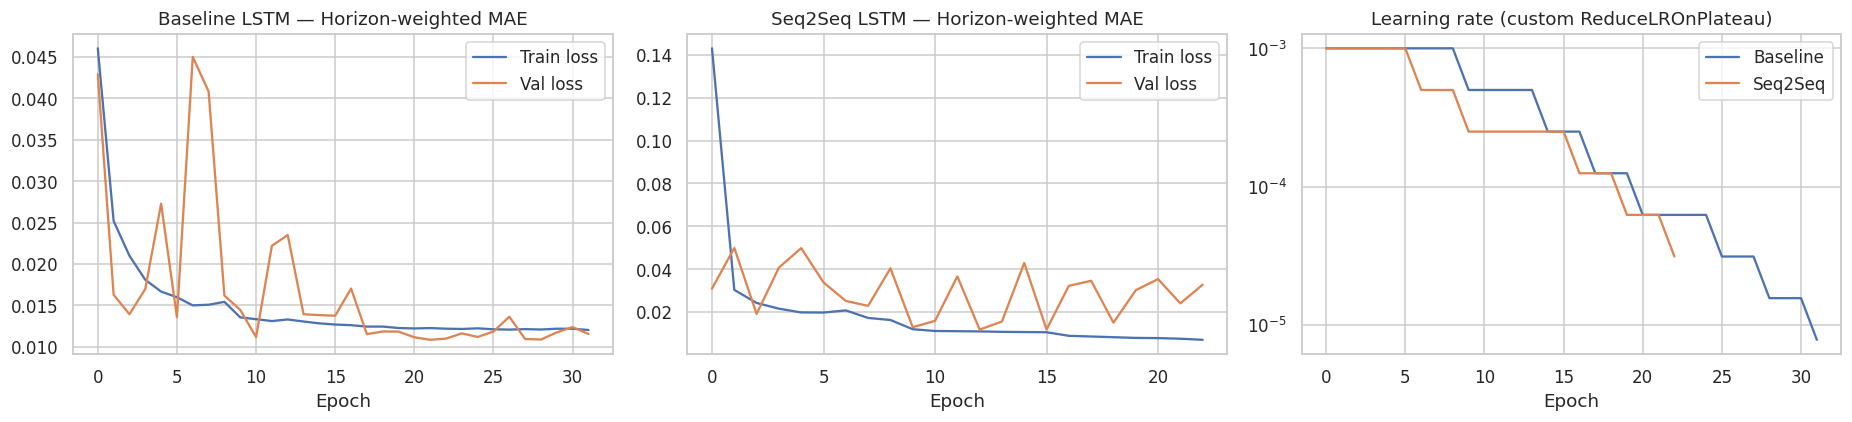

In [25]:
es_seq2seq = CustomEarlyStopping(patience=ES_PATIENCE, min_delta=ES_MIN_DELTA, restore_best_weights=False)
lr_seq2seq = CustomReduceLROnPlateau(factor=LR_FACTOR, patience=LR_PATIENCE, min_delta=LR_MIN_DELTA, min_lr=LR_MIN)
 
history_seq2seq = fit_custom(seq2seq_model, "Seq2Seq LSTM (Teacher Forcing)", s2s_forward_train, s2s_forward_eval,
                             weighted_loss_fn, es_seq2seq, lr_seq2seq)
 
# %%
# Training curves
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
for ax, (title, h) in zip(axes[:2], [("Baseline LSTM", history_baseline), ("Seq2Seq LSTM", history_seq2seq)]):
    ax.plot(h["loss"], label="Train loss")
    ax.plot(h["val_loss"], label="Val loss")
    ax.set_title(f"{title} — Horizon-weighted MAE")
    ax.set_xlabel("Epoch"); ax.legend()
axes[2].plot(history_baseline["lr"], label="Baseline")
axes[2].plot(history_seq2seq["lr"], label="Seq2Seq")
axes[2].set_yscale("log"); axes[2].set_title("Learning rate (custom ReduceLROnPlateau)")
axes[2].set_xlabel("Epoch"); axes[2].legend()
plt.tight_layout(); plt.show()


### 5. Test Inference & Evaluation
#### * Baseline LSTM: direct multi-step prediction.
#### * Seq2Seq LSTM: **autoregressive** decoding (each prediction is fed back as the next decoder input; no ground truth is used).
#### * Main metric: **MAE on the scaled test set** (before inverse scaling), target < 0.015.

,MAE (scaled),RMSE (scaled),MAE (USD),RMSE (USD),MAPE (%)
Model,,,,,
Baseline LSTM,0.00971,0.01225,635.87,801.91,2.448
Naive (last value) [reference],0.00360,0.00603,235.61,394.71,0.932
"Seq2Seq LSTM (final epoch, autoregressive)",0.01822,0.02169,"1,192.80","1,420.15",4.749
"Seq2Seq LSTM (best val, epoch 13, autoregressive)",0.00767,0.01041,501.89,681.62,1.980


[PASS] Baseline LSTM : test MAE (scaled) = 0.00971  (target < 0.015)
[FAIL] Seq2Seq final : test MAE (scaled) = 0.01822  (target < 0.015)
[PASS] Seq2Seq best  : test MAE (scaled) = 0.00767  (target < 0.015)


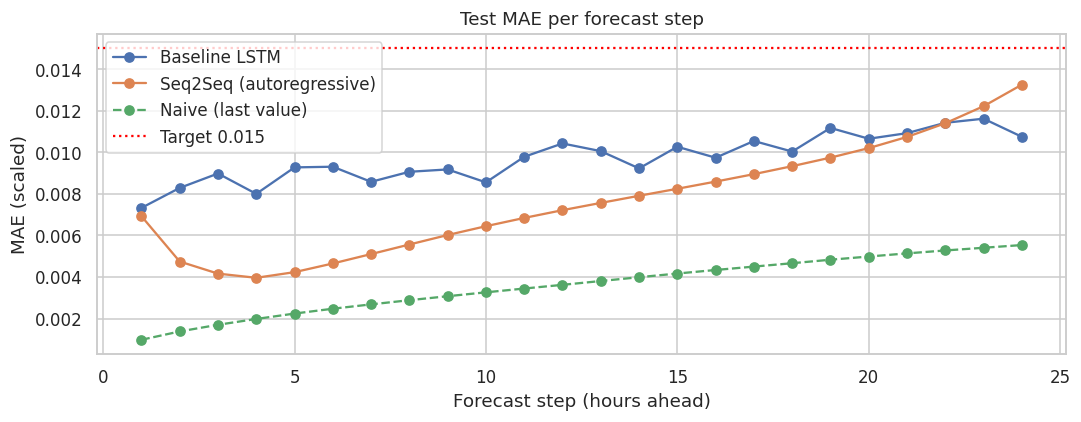

In [26]:
@tf.function(reduce_retracing=True)
def predict_baseline(x):
    return baseline_model(x, training=False)
 
 
@tf.function(reduce_retracing=True)
def predict_seq2seq_autoregressive(x):
    return seq2seq_model.autoregressive_predict(x)
 
 
def predict_on_test(predict_fn):
    """Runs a model over test_ds. Returns (y_true, y_pred, last_known_close), all scaled, shapes (N,H,1)/(N,H,1)/(N,)."""
    trues, preds, lasts = [], [], []
    for (x, _dec), y in test_ds:
        preds.append(predict_fn(x).numpy())
        trues.append(y.numpy())
        lasts.append(x[:, -1, TARGET_IDX].numpy())
    return np.concatenate(trues), np.concatenate(preds), np.concatenate(lasts)
 
 
def compute_metrics(name, y_true, y_pred):
    err = y_true - y_pred
    usd_true, usd_pred = inverse_close(y_true), inverse_close(y_pred)
    return {
        "Model": name,
        "MAE (scaled)": float(np.mean(np.abs(err))),
        "RMSE (scaled)": float(np.sqrt(np.mean(err ** 2))),
        "MAE (USD)": float(np.mean(np.abs(usd_true - usd_pred))),
        "RMSE (USD)": float(np.sqrt(np.mean((usd_true - usd_pred) ** 2))),
        "MAPE (%)": float(np.mean(np.abs((usd_true - usd_pred) / usd_true)) * 100),
    }
 
 
results, predictions = [], {}
 
# --- Baseline LSTM (best weights restored by early stopping) ---
y_test, p_baseline, last_close = predict_on_test(predict_baseline)
predictions["Baseline LSTM"] = p_baseline
results.append(compute_metrics("Baseline LSTM", y_test, p_baseline))
 
# --- Naive persistence reference: repeat the last known Close for all 24 steps ---
p_naive = np.repeat(last_close[:, None, None], HORIZON, axis=1)
predictions["Naive (last value)"] = p_naive
results.append(compute_metrics("Naive (last value) [reference]", y_test, p_naive))
 
# --- Seq2Seq LSTM, final (last-epoch) weights — autoregressive ---
_, p_s2s_final, _ = predict_on_test(predict_seq2seq_autoregressive)
predictions["Seq2Seq (final)"] = p_s2s_final
results.append(compute_metrics("Seq2Seq LSTM (final epoch, autoregressive)", y_test, p_s2s_final))
final_weights = seq2seq_model.get_weights()
 
# Save final-epoch Seq2Seq + baseline now (before swapping weights)
baseline_path = os.path.join(WORKING_DIR, "model_baseline_LSTM.keras")
seq2seq_path = os.path.join(WORKING_DIR, "model_seq2seq_LSTM.keras")
best_path = os.path.join(WORKING_DIR, "best_model_seq2seq_LSTM.keras")
baseline_model.save(baseline_path)
seq2seq_model.save(seq2seq_path)
 
# --- Seq2Seq LSTM, best-validation weights — autoregressive ---
seq2seq_model.set_weights(es_seq2seq.best_weights)
_, p_s2s_best, _ = predict_on_test(predict_seq2seq_autoregressive)
predictions["Seq2Seq (best val)"] = p_s2s_best
results.append(compute_metrics(f"Seq2Seq LSTM (best val, epoch {es_seq2seq.best_epoch}, autoregressive)",
                               y_test, p_s2s_best))
seq2seq_model.save(best_path)
 
results_df = pd.DataFrame(results).set_index("Model")
show(results_df.style.format({"MAE (scaled)": "{:.5f}", "RMSE (scaled)": "{:.5f}", "MAE (USD)": "{:,.2f}",
                              "RMSE (USD)": "{:,.2f}", "MAPE (%)": "{:.3f}"}))
 
for label, p in [("Baseline LSTM", p_baseline), ("Seq2Seq final", p_s2s_final), ("Seq2Seq best", p_s2s_best)]:
    mae = float(np.mean(np.abs(y_test - p)))
    status = "PASS" if mae < MAE_TARGET else "FAIL"
    print(f"[{status}] {label:<14}: test MAE (scaled) = {mae:.5f}  (target < {MAE_TARGET})")
 
# %%
# MAE per forecast step (shows error growth with horizon)
steps = np.arange(1, HORIZON + 1)
plt.figure(figsize=(10, 4))
plt.plot(steps, np.mean(np.abs(y_test - p_baseline), axis=(0, 2)), marker="o", label="Baseline LSTM")
plt.plot(steps, np.mean(np.abs(y_test - p_s2s_best), axis=(0, 2)), marker="o", label="Seq2Seq (autoregressive)")
plt.plot(steps, np.mean(np.abs(y_test - p_naive), axis=(0, 2)), marker="o", linestyle="--", label="Naive (last value)")
plt.axhline(MAE_TARGET, color="red", linestyle=":", label=f"Target {MAE_TARGET}")
plt.xlabel("Forecast step (hours ahead)"); plt.ylabel("MAE (scaled)")
plt.title("Test MAE per forecast step"); plt.legend(); plt.tight_layout(); plt.show()
 

### 6. Visualisation — Actual vs Predicted (USD) and Comparison Table
#### Windows have stride 1, so for a continuous chart the **non-overlapping 24-hour forecasts** (window 0, 24, 48, …)
#### are stitched together across the whole test period.

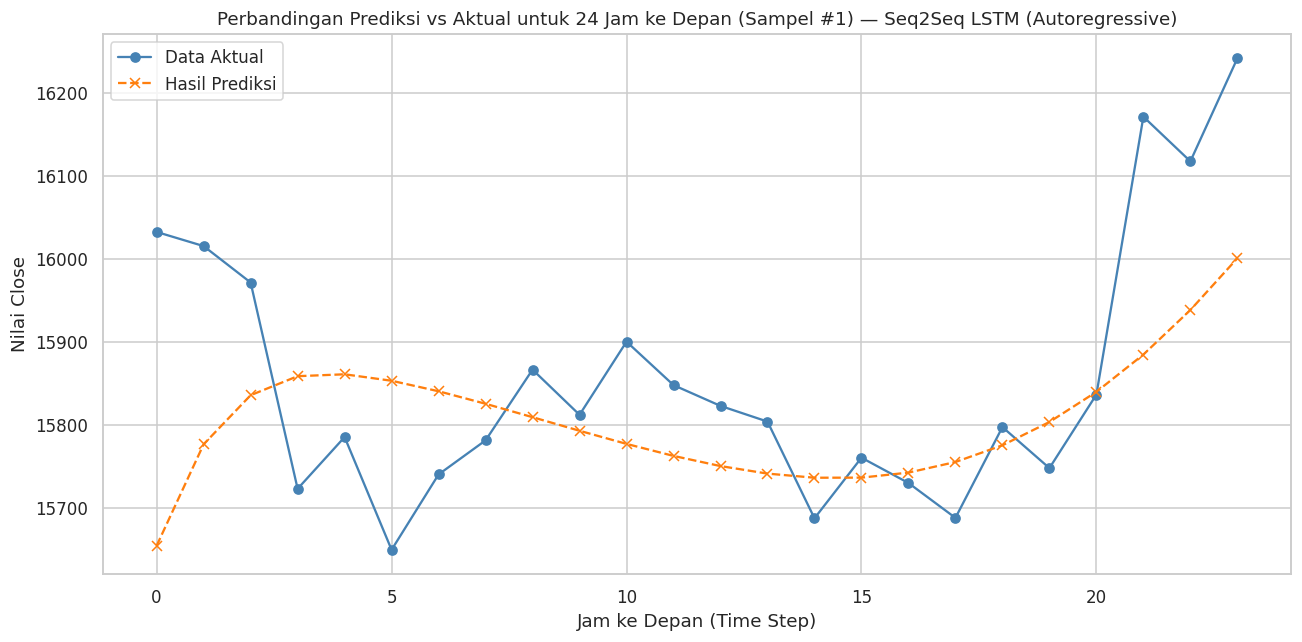

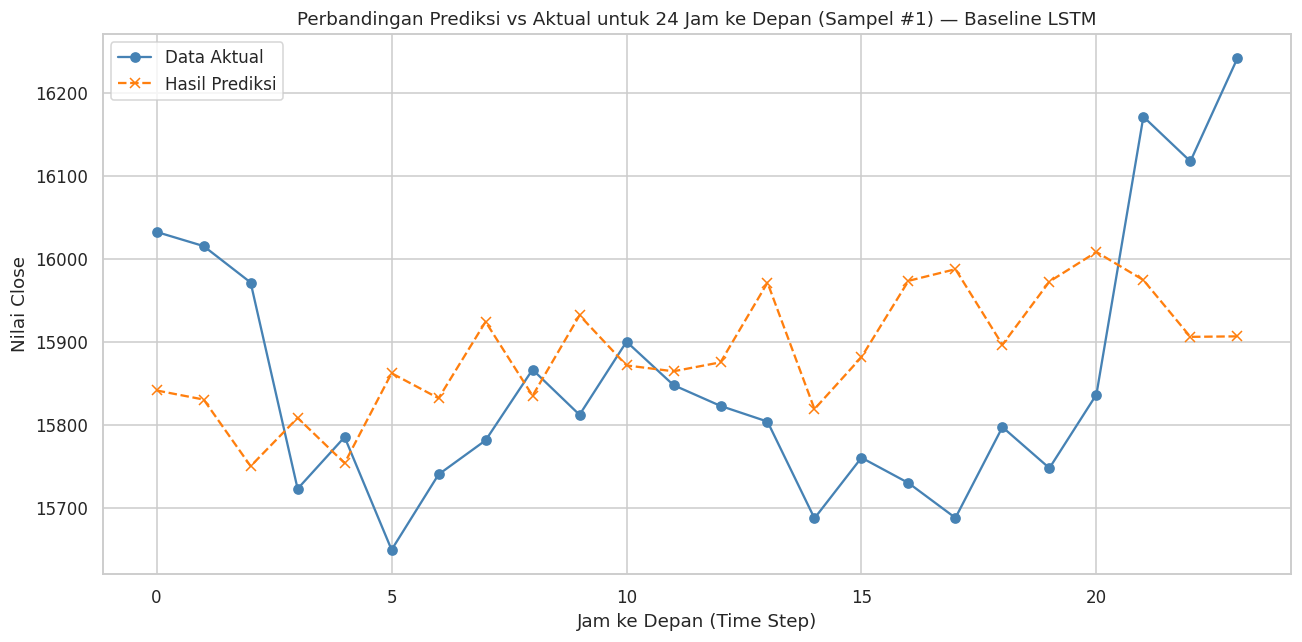

In [27]:
def plot_prediksi_24_jam(y_true_scaled, y_pred_scaled, model_name, sample_idx=0):
    """Line chart satu window prediksi 24 jam (dalam USD), mengikuti format contoh."""
    aktual = inverse_close(y_true_scaled[sample_idx, :, 0])
    prediksi = inverse_close(y_pred_scaled[sample_idx, :, 0])
    jam = np.arange(HORIZON)                                    # 0 ... 23
 
    plt.figure(figsize=(12, 6))
    plt.plot(jam, aktual, marker="o", linestyle="-", color="steelblue", label="Data Aktual")
    plt.plot(jam, prediksi, marker="x", linestyle="--", color="tab:orange", label="Hasil Prediksi")
    plt.title(f"Perbandingan Prediksi vs Aktual untuk 24 Jam ke Depan (Sampel #{sample_idx + 1}) — {model_name}")
    plt.xlabel("Jam ke Depan (Time Step)")
    plt.ylabel("Nilai Close")
    plt.grid(True)
    plt.legend()
    plt.tight_layout()
    plt.show()
 
 
plot_prediksi_24_jam(y_test, p_s2s_best, "Seq2Seq LSTM (Autoregressive)")
plot_prediksi_24_jam(y_test, p_baseline, "Baseline LSTM")

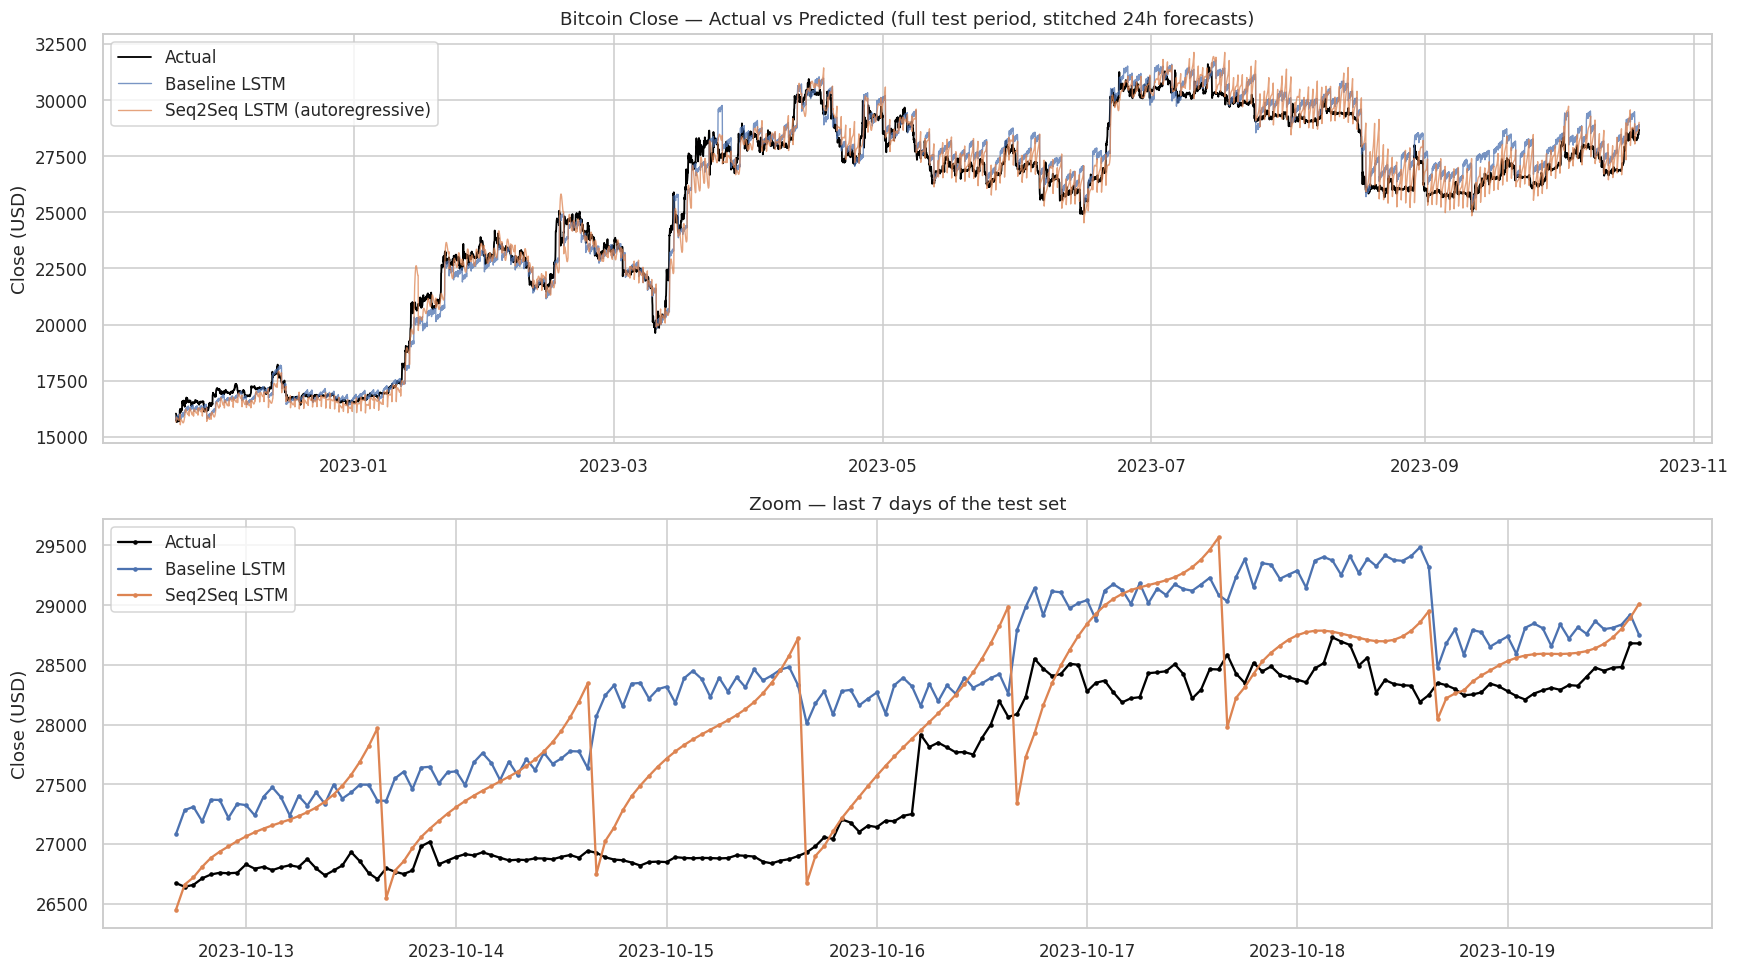

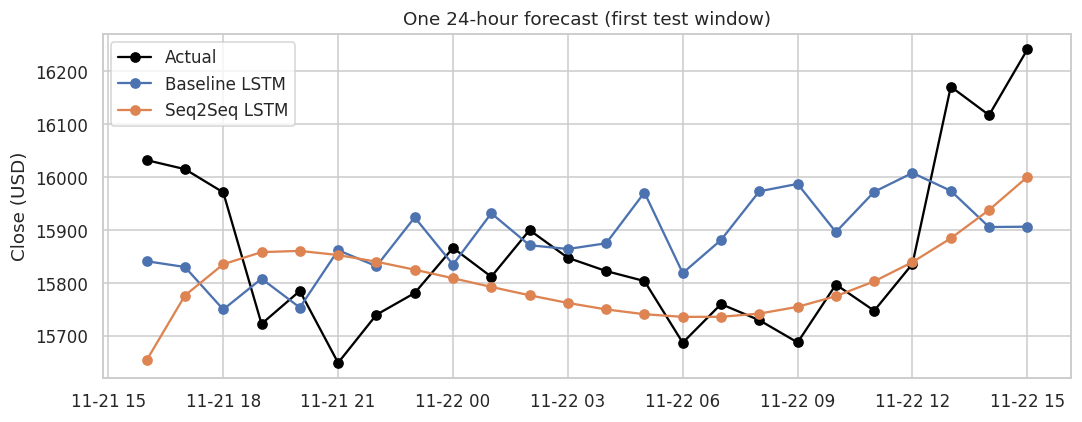

Seq2Seq LSTM (autoregressive) — 24 jam ke depan:


,Jam ke,Data Aktual,Hasil Prediksi,Selisih
0,1,16032.24,15654.482129,377.757417
1,2,16015.22,15776.624633,238.595183
2,3,15971.36,15835.670842,135.689616
3,4,15722.98,15858.578414,-135.598899
4,5,15785.27,15860.860977,-75.590892
5,6,15649.52,15853.076851,-203.556859
6,7,15740.27,15840.427158,-100.156737
7,8,15781.29,15825.354435,-44.064204
8,9,15866.48,15809.204812,57.274783
9,10,15812.06,15792.852293,19.207674


Baseline LSTM — 24 jam ke depan:


,Jam ke,Data Aktual,Hasil Prediksi,Selisih
0,1,16032.24,15841.373348,190.866197
1,2,16015.22,15830.441430,184.778385
2,3,15971.36,15750.232737,221.127720
3,4,15722.98,15808.384454,-85.404939
4,5,15785.27,15753.889716,31.380370
5,6,15649.52,15862.145651,-212.625659
6,7,15740.27,15832.012888,-91.742466
7,8,15781.29,15924.123100,-142.832869
8,9,15866.48,15835.032895,31.446701
9,10,15812.06,15931.870160,-119.810193


In [29]:
n_windows = y_test.shape[0]
starts = np.arange(0, n_windows, HORIZON)
positions = np.concatenate([np.arange(s, s + HORIZON) for s in starts])
stitched_index = test_index[positions]
 
 
def stitched_series(arr):
    return inverse_close(arr[starts, :, 0]).reshape(-1)
 
 
actual_usd = stitched_series(y_test)
pred_usd = {"Baseline LSTM": stitched_series(p_baseline), "Seq2Seq LSTM": stitched_series(p_s2s_best)}
 
# --- Line charts ---
fig, axes = plt.subplots(2, 1, figsize=(16, 9))
axes[0].plot(stitched_index, actual_usd, label="Actual", color="black", linewidth=1.2)
axes[0].plot(stitched_index, pred_usd["Baseline LSTM"], label="Baseline LSTM", alpha=0.75, linewidth=0.9)
axes[0].plot(stitched_index, pred_usd["Seq2Seq LSTM"], label="Seq2Seq LSTM (autoregressive)", alpha=0.75, linewidth=0.9)
axes[0].set_title("Bitcoin Close — Actual vs Predicted (full test period, stitched 24h forecasts)")
axes[0].set_ylabel("Close (USD)"); axes[0].legend()
 
zoom = 24 * 7                                                     # last 7 days of the test period
axes[1].plot(stitched_index[-zoom:], actual_usd[-zoom:], label="Actual", color="black", marker="o", markersize=2)
axes[1].plot(stitched_index[-zoom:], pred_usd["Baseline LSTM"][-zoom:], label="Baseline LSTM", marker="o", markersize=2)
axes[1].plot(stitched_index[-zoom:], pred_usd["Seq2Seq LSTM"][-zoom:], label="Seq2Seq LSTM", marker="o", markersize=2)
axes[1].set_title("Zoom — last 7 days of the test set")
axes[1].set_ylabel("Close (USD)"); axes[1].legend()
plt.tight_layout(); plt.show()
 
# --- Single 24h forecast example (first test window) ---
plt.figure(figsize=(10, 4))
w0_idx = test_index[0:HORIZON]
plt.plot(w0_idx, inverse_close(y_test[0, :, 0]), label="Actual", color="black", marker="o")
plt.plot(w0_idx, inverse_close(p_baseline[0, :, 0]), label="Baseline LSTM", marker="o")
plt.plot(w0_idx, inverse_close(p_s2s_best[0, :, 0]), label="Seq2Seq LSTM", marker="o")
plt.title("One 24-hour forecast (first test window)"); plt.ylabel("Close (USD)"); plt.legend()
plt.tight_layout(); plt.show()
 
# %%
# --- Comparison tables: Actual | Predicted | Selisih ---
def build_comparison_table(y_true_scaled, y_pred_scaled, window_idx=0):
    """Tabel perbandingan untuk SATU window prediksi 24 jam (Jam ke 1 ... 24), dalam USD."""
    actual = inverse_close(y_true_scaled[window_idx, :, 0])
    pred = inverse_close(y_pred_scaled[window_idx, :, 0])
    table = pd.DataFrame({
        "Jam ke": np.arange(1, HORIZON + 1),
        "Data Aktual": np.round(actual, 2),
        "Hasil Prediksi": pred,
        "Selisih": actual - pred,          # Selisih = Data Aktual - Hasil Prediksi
    })
    return table
 
tabel_seq2seq = build_comparison_table(y_test, p_s2s_best)
tabel_baseline = build_comparison_table(y_test, p_baseline)
 
print("Seq2Seq LSTM (autoregressive) — 24 jam ke depan:")
show(tabel_seq2seq)
 
print("Baseline LSTM — 24 jam ke depan:")
show(tabel_baseline)
 
# Opsional: simpan sebagai CSV
tabel_seq2seq.to_csv(os.path.join(WORKING_DIR, "tabel_perbandingan_seq2seq.csv"), index=False)
tabel_baseline.to_csv(os.path.join(WORKING_DIR, "tabel_perbandingan_baseline.csv"), index=False)
 

### 7. Verify Saved Models, Generate `requirements.txt`


In [30]:
# Reload every saved .keras file and compare with the in-memory predictions of the first test batch
(x_first, _), _ = next(iter(test_ds))
n_first = x_first.shape[0]
 
loaded_baseline = keras.models.load_model(baseline_path)
loaded_final = keras.models.load_model(seq2seq_path)
loaded_best = keras.models.load_model(best_path)
 
checks = [
    ("model_baseline_LSTM.keras", loaded_baseline(x_first, training=False).numpy(), p_baseline[:n_first]),
    ("model_seq2seq_LSTM.keras", loaded_final.autoregressive_predict(x_first).numpy(), p_s2s_final[:n_first]),
    ("best_model_seq2seq_LSTM.keras", loaded_best.autoregressive_predict(x_first).numpy(), p_s2s_best[:n_first]),
]
for fname, reloaded_pred, original_pred in checks:
    diff = float(np.abs(reloaded_pred - original_pred).max())
    print(f"{fname:<32} reload OK | max abs diff vs in-memory predictions: {diff:.2e}")
    assert diff < 1e-4, f"{fname} does not reproduce the original predictions!"
 
# %%
# requirements.txt — only the libraries imported in this project, with the versions installed in this session
PACKAGES = ["tensorflow", "keras", "numpy", "pandas", "scikit-learn", "statsmodels",
            "matplotlib", "seaborn", "joblib"]
lines = []
for pkg in PACKAGES:
    try:
        lines.append(f"{pkg}=={importlib_metadata.version(pkg)}")
    except importlib_metadata.PackageNotFoundError:
        print(f"(skipped, not installed: {pkg})")
 
requirements_path = os.path.join(WORKING_DIR, "requirements.txt")
with open(requirements_path, "w") as f:
    f.write("\n".join(lines) + "\n")
print(open(requirements_path).read())
 
# %%
# Final deliverables
print("Files in", os.path.abspath(WORKING_DIR))
for fname in ["model_baseline_LSTM.keras", "model_seq2seq_LSTM.keras", "best_model_seq2seq_LSTM.keras", "requirements.txt"]:
    fpath = os.path.join(WORKING_DIR, fname)
    print(f"  {'OK ' if os.path.exists(fpath) else 'MISSING'} {fname:<32} "
          f"{os.path.getsize(fpath) / 1024:,.1f} KB" if os.path.exists(fpath) else f"  MISSING {fname}")
 
best_mae = float(np.mean(np.abs(y_test - p_s2s_best)))
print(f"\nSeq2Seq LSTM (autoregressive, best val) test MAE (scaled): {best_mae:.5f}  "
      f"-> {'meets' if best_mae < MAE_TARGET else 'DOES NOT meet'} the < {MAE_TARGET} target")
 

model_baseline_LSTM.keras        reload OK | max abs diff vs in-memory predictions: 5.96e-08
model_seq2seq_LSTM.keras         reload OK | max abs diff vs in-memory predictions: 4.77e-07
best_model_seq2seq_LSTM.keras    reload OK | max abs diff vs in-memory predictions: 3.58e-07
tensorflow==2.20.0
keras==3.13.2
numpy==2.1.3
pandas==2.3.3
scikit-learn==1.6.1
statsmodels==0.15.0
matplotlib==3.10.0
seaborn==0.13.2
joblib==1.6.0

Files in /kaggle/working
  OK  model_baseline_LSTM.keras        1,179.0 KB
  OK  model_seq2seq_LSTM.keras         895.9 KB
  OK  best_model_seq2seq_LSTM.keras    895.9 KB
  OK  requirements.txt                 0.1 KB

Seq2Seq LSTM (autoregressive, best val) test MAE (scaled): 0.00767  -> meets the < 0.015 target
